# **Project Name**    - Voyage Analytics : Integrating MLOps in Travel



### Import Libraries

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from datetime import datetime
import datetime as dt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import RandomizedSearchCV , cross_val_score, KFold
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import log_loss
import warnings
warnings.filterwarnings('ignore')

### Dataset First View

In [100]:
user = pd.read_csv('users.csv', encoding='latin1')
user

,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44
...,...,...,...,...,...
1335,1335,Umbrella LTDA,Albert Garroutte,male,23
1336,1336,Umbrella LTDA,Kim Shores,female,40
1337,1337,Umbrella LTDA,James Gimenez,male,28
1338,1338,Umbrella LTDA,Viola Agosta,female,52


In [101]:
flight = pd.read_csv("flights.csv", encoding='latin1')
flight

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,10/04/2019
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,10/10/2019
...,...,...,...,...,...,...,...,...,...,...
271883,135941,1339,Campo Grande (MS),Florianopolis (SC),firstClass,1446.34,1.49,573.81,CloudFy,07/12/2020
271884,135942,1339,Florianopolis (SC),Natal (RN),economic,726.95,1.84,709.37,CloudFy,07/16/2020
271885,135942,1339,Natal (RN),Florianopolis (SC),economic,873.07,1.84,709.37,CloudFy,07/20/2020
271886,135943,1339,Florianopolis (SC),Rio de Janeiro (RJ),economic,313.62,1.21,466.30,CloudFy,07/23/2020


In [102]:
hotel = pd.read_csv("hotels.csv", encoding='latin1')
hotel

,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,09/26/2019
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,10/10/2019
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,11/14/2019
3,11,0,Hotel K,Salvador (BH),4,263.41,1053.64,12/12/2019
4,13,0,Hotel A,Florianopolis (SC),1,313.02,313.02,12/26/2019
...,...,...,...,...,...,...,...,...
40547,135938,1339,Hotel BP,Brasilia (DF),3,247.62,742.86,06/18/2020
40548,135939,1339,Hotel BP,Brasilia (DF),1,247.62,247.62,06/25/2020
40549,135940,1339,Hotel BW,Campo Grande (MS),3,60.39,181.17,07/02/2020
40550,135941,1339,Hotel BW,Campo Grande (MS),3,60.39,181.17,07/09/2020


In [6]:
# Rename the column
hotel.rename(columns={'name':'hotel_name','price':'hotel_price','date':'hotel_date'},inplace=True)

In [7]:
from typing_extensions import final
# Merge flight and users on the common column userCode
flight_users = pd.merge(flight, user, left_on='userCode', right_on='code', how='left')

# Merge the result which is flight_users with hotels on common columns travelCode and userCode
travel_data = pd.merge(flight_users, hotel, on=['travelCode', 'userCode'], how='left')

In [8]:
#Final dataset
travel_data.head()

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date,...,company,name,gender,age,hotel_name,place,days,hotel_price,total,hotel_date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019,...,4You,Roy Braun,male,21,Hotel A,Florianopolis (SC),4.0,313.02,1252.08,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019,...,4You,Roy Braun,male,21,Hotel A,Florianopolis (SC),4.0,313.02,1252.08,09/26/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019,...,4You,Roy Braun,male,21,NaN,NaN,NaN,NaN,NaN,NaN
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,10/04/2019,...,4You,Roy Braun,male,21,NaN,NaN,NaN,NaN,NaN,NaN
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,10/10/2019,...,4You,Roy Braun,male,21,Hotel K,Salvador (BH),2.0,263.41,526.82,10/10/2019


### Dataset Rows & Columns count

In [9]:
# Dataset Rows & Columns count
travel_data.shape

(271888, 21)

### Dataset Information

In [10]:
# Dataset Info
travel_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 21 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   travelCode   271888 non-null  int64  
 1   userCode     271888 non-null  int64  
 2   from         271888 non-null  object 
 3   to           271888 non-null  object 
 4   flightType   271888 non-null  object 
 5   price        271888 non-null  float64
 6   time         271888 non-null  float64
 7   distance     271888 non-null  float64
 8   agency       271888 non-null  object 
 9   date         271888 non-null  object 
 10  code         271888 non-null  int64  
 11  company      271888 non-null  object 
 12  name         271888 non-null  object 
 13  gender       271888 non-null  object 
 14  age          271888 non-null  int64  
 15  hotel_name   81104 non-null   object 
 16  place        81104 non-null   object 
 17  days         81104 non-null   float64
 18  hotel_price  81104 non-n

#### Duplicate Values

In [11]:
# Dataset Duplicate Value Count
travel_data.duplicated().sum()

0

#### Missing Values/Null Values

In [12]:
# Missing Values/Null Values Count
travel_data.isnull().sum()

travelCode          0
userCode            0
from                0
to                  0
flightType          0
price               0
time                0
distance            0
agency              0
date                0
code                0
company             0
name                0
gender              0
age                 0
hotel_name     190784
place          190784
days           190784
hotel_price    190784
total          190784
hotel_date     190784
dtype: int64

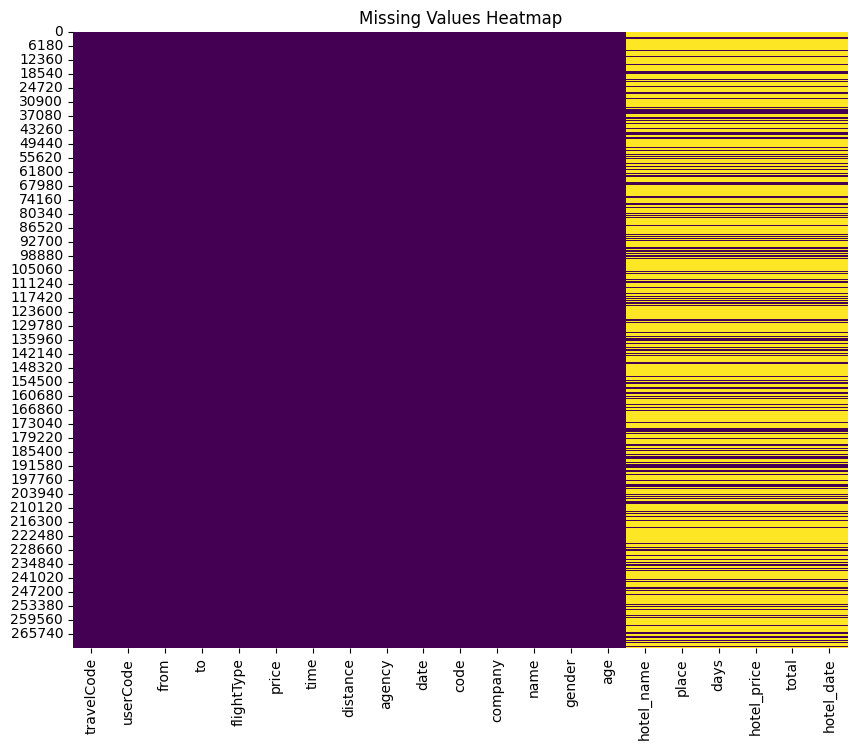

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(travel_data.isnull(), cmap='viridis', cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

### What did you know about your dataset?



1. The travel_data DataFrame has 271,888 rows and 21 columns, combining flight and user information, with optional hotel details.


2. It's composed of both numerical and categorical data types. A significant observation is the presence of 190,784 missing values in all hotel-related columns, suggesting that not every flight booking includes a hotel.


3. There are no duplicate entries.


4. Numerically, flight price averages around 957, flight time around 1.42 hours, and distance around 546. User age averages 42. Hotel bookings, when present, typically last 1 to 4 days, with hotel_price averaging around 214.



## ***2. Understanding Your Variables***

In [16]:
# Dataset columns
travel_data.columns

Index(['travelCode', 'userCode', 'from', 'to', 'flightType', 'price', 'time',
       'distance', 'agency', 'date', 'code', 'company', 'name', 'gender',
       'age', 'hotel_name', 'place', 'days', 'hotel_price', 'total',
       'hotel_date'],
      dtype='object')

In [17]:
# Dataset Describe
travel_data.describe().T

,count,mean,std,min,25%,50%,75%,max
travelCode,271888.0,67971.500000,39243.724665,0.00,33985.75,67971.50,101957.25,135943.00
userCode,271888.0,667.505495,389.523127,0.00,326.00,659.00,1011.00,1339.00
price,271888.0,957.375030,362.311890,301.51,672.66,904.00,1222.24,1754.17
time,271888.0,1.421147,0.542541,0.44,1.04,1.46,1.76,2.44
distance,271888.0,546.955535,208.851288,168.22,401.66,562.14,676.53,937.77
code,271888.0,667.505495,389.523127,0.00,326.00,659.00,1011.00,1339.00
age,271888.0,42.815005,12.946294,21.00,32.00,42.00,54.00,65.00
days,81104.0,2.499679,1.119319,1.00,1.00,2.00,4.00,4.00
hotel_price,81104.0,214.439554,76.741832,60.39,165.99,242.88,263.41,313.02
total,81104.0,536.229513,319.329514,60.39,247.62,495.24,742.86,1252.08


### Check Unique Values for each variable.

In [18]:
# Check Unique Values for each variable.
def unique_values(df):
    for col in df.columns:
        unique_count = df[col].nunique()
        a=print(f"{col} : {unique_count}")
    return a

In [19]:
unique_values(travel_data)

travelCode : 135944
userCode : 1335
from : 9
to : 9
flightType : 3
price : 490
time : 33
distance : 35
agency : 3
date : 999
code : 1335
company : 5
name : 1333
gender : 3
age : 45
hotel_name : 9
place : 9
days : 4
hotel_price : 9
total : 36
hotel_date : 199


## 3. ***Data Wrangling***

### Data Wrangling Code

In [20]:
# Drop the 'code' column as it is a duplicate of 'userCode'.
travel_data.drop('code', axis=1, inplace=True)

In [21]:
# Converted 'date' and 'hotel_date' columns to datetime
travel_data['date'] = pd.to_datetime(travel_data['date'])
travel_data['hotel_date'] = pd.to_datetime(travel_data['hotel_date'])

In [22]:
# Filling missing values in 'hotel_name' and 'place' with 'No Hotel'
travel_data['hotel_name'].fillna('No Hotel', inplace=True)
travel_data['place'].fillna('No Hotel', inplace=True)


In [23]:
# Filling missing values in 'days', 'hotel_price', and 'total' with 0.
travel_data['days'].fillna(0, inplace=True)
travel_data['hotel_price'].fillna(0, inplace=True)
travel_data['total'].fillna(0, inplace=True)


In [24]:

# function for selecting all the numerical columns
def numerical_col(df):
  c = []
  for col in df.columns:
    if df[col].dtype =='int' or df[col].dtype =='float':
       c.append(col)
  return c
numerical_col(travel_data)



['price', 'time', 'distance', 'days', 'hotel_price', 'total']

In [25]:
# function for selecting all the categorical columns
def categorical_col(df):
  d = []
  for col in df.columns:
    if df[col].dtype == 'O':
       d.append(col)
  return d
categorical_col(travel_data)

['from',
 'to',
 'flightType',
 'agency',
 'company',
 'name',
 'gender',
 'hotel_name',
 'place']

### Data Wrangling Key Findings

*   The duplicate 'code' column was successfully dropped from the `travel_data` DataFrame.
*   The 'date' and 'hotel\_date' columns were successfully converted to `datetime64[ns]` objects.
*   Missing values in the 'hotel\_name' and 'place' columns were imputed with 'No Hotel'.
*   Missing values in the numerical columns 'days', 'hotel\_price', and 'total' were imputed with 0.
*   After the wrangling steps, the 'hotel\_name', 'place', 'days', 'hotel\_price', and 'total' columns no longer contain any missing values.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

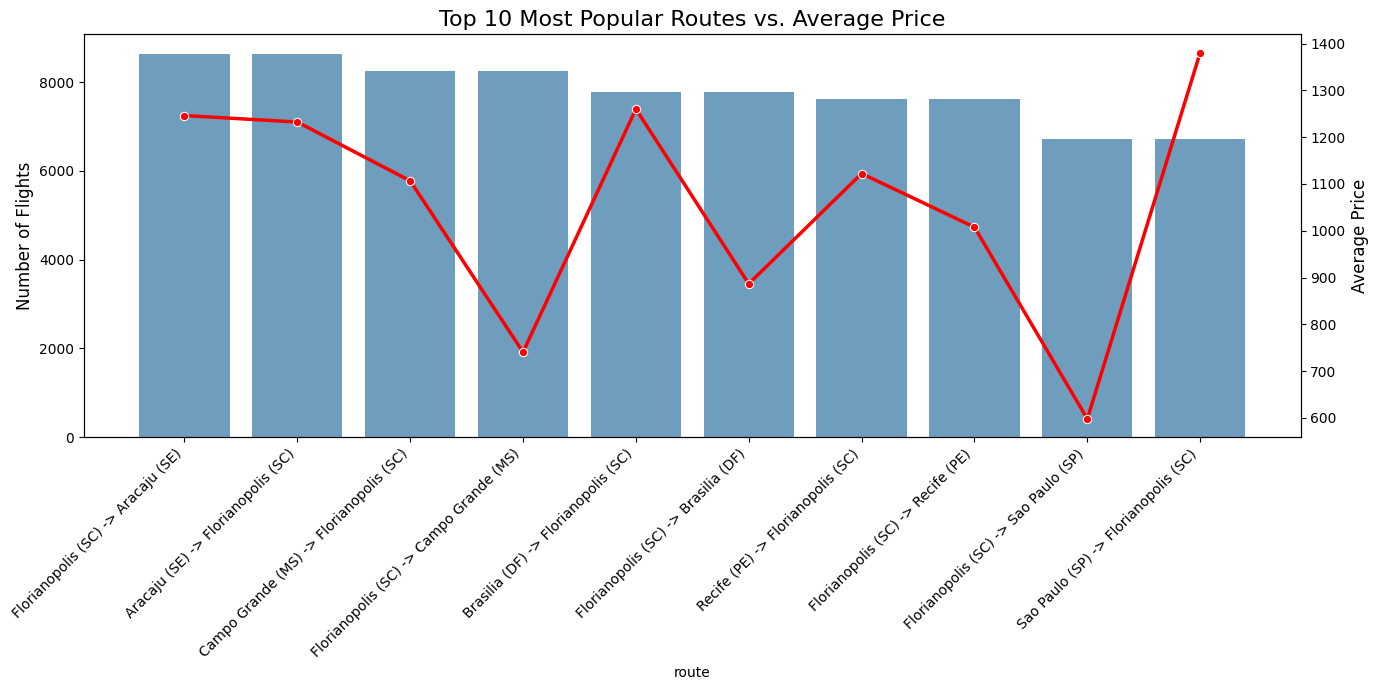

In [27]:
# Analyzing Top 10 Most Frequent Travel Routes and their Average Prices
route_stats = flight.groupby(['from', 'to']).agg(
    flight_count=('price', 'count'),
    avg_price=('price', 'mean')
).reset_index()

# Create a Route name column
route_stats['route'] = route_stats['from'] + ' -> ' + route_stats['to']

# Sort by frequency and take top 10
top_routes = route_stats.sort_values(by='flight_count', ascending=False).head(10)

# Visualization
fig, ax1 = plt.subplots(figsize=(14, 7))

# Bar plot for flight frequency
sns.barplot(x='route', y='flight_count', data=top_routes, ax=ax1, alpha=0.7)
ax1.set_ylabel('Number of Flights', fontsize=12)
ax1.tick_params(axis='y')
plt.xticks(rotation=45, ha='right')

# Create a second y-axis for average price
ax2 = ax1.twinx()
sns.lineplot(x='route', y='avg_price', data=top_routes, ax=ax2, color='red', marker='o', linewidth=2.5)
ax2.set_ylabel('Average Price', fontsize=12)
ax2.tick_params(axis='y')

plt.title('Top 10 Most Popular Routes vs. Average Price', fontsize=16)
fig.tight_layout()
plt.show()

High-Demand Routes: The route from 'Aracaju (SE)' to 'Florianopolis (SC)' and its return leg are the most frequent, both seeing over 8,000 flights.


Price Stability: Interestingly, despite high volume, these top routes maintain some of the highest average prices (over 1,200), suggesting strong pricing power or high-value business demand on these specific paths.


Value Opportunities: Routes like 'Florianopolis (SC)' to 'Natal (RN)' show significant volume but much lower average prices (around 700), indicating a more budget-friendly or leisure-oriented market segment.

#### Chart - 2

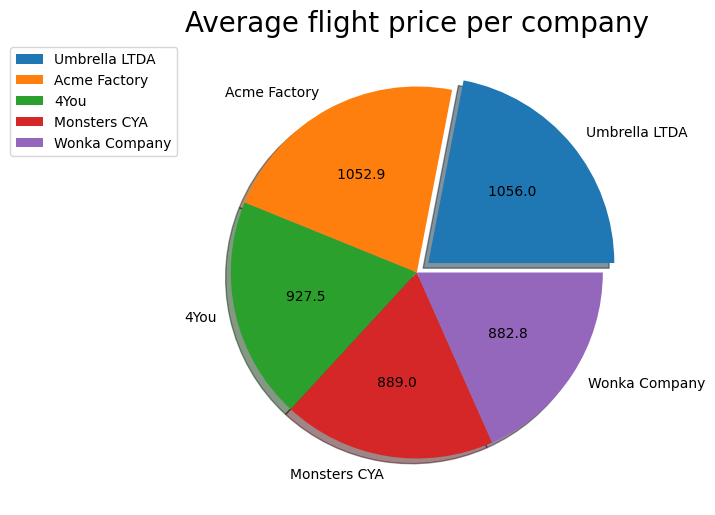

In [29]:
# Chart - 2 visualization code
plt.rcParams['figure.figsize']=(6,8)  
ee_company = travel_data.groupby('company')['price'].mean().sort_values(ascending=False)
myexplode_company = [0.08, 0, 0, 0, 0] 
plt.title('Average flight price per company',fontsize=20) 
def func(pct, allvalues):
    absolute = pct/100.*np.sum(allvalues)
    return "{:.1f} ".format(absolute)
plt.pie(ee_company,labels=ee_company.index,explode=myexplode_company,autopct=lambda pct: func(pct, ee_company),shadow=True) # Using company names as labels and a custom autopct function
plt.legend(bbox_to_anchor=(0,1)); # Used to display and adjust the position of information box that is present on the left side of this pie chart



A pie chart is used to display the average flight price for each 'company'. This choice is effective for illustrating the relative pricing scales of different companies within the dataset. It allows for a quick visual comparison, highlighting which companies tend to have higher or lower average prices, similar to how the agency pie chart was used to compare pricing strategies.

#### Chart - 3

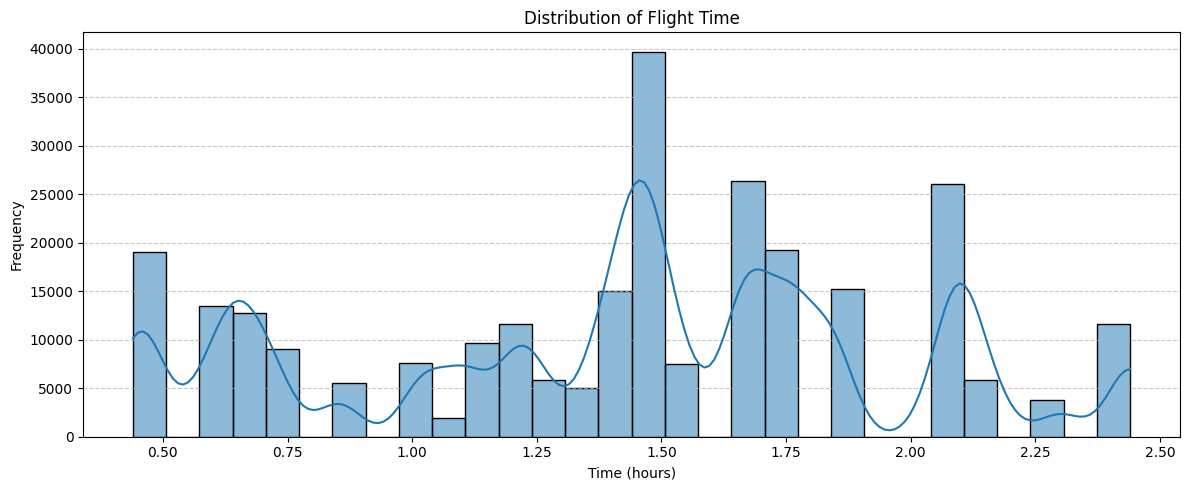

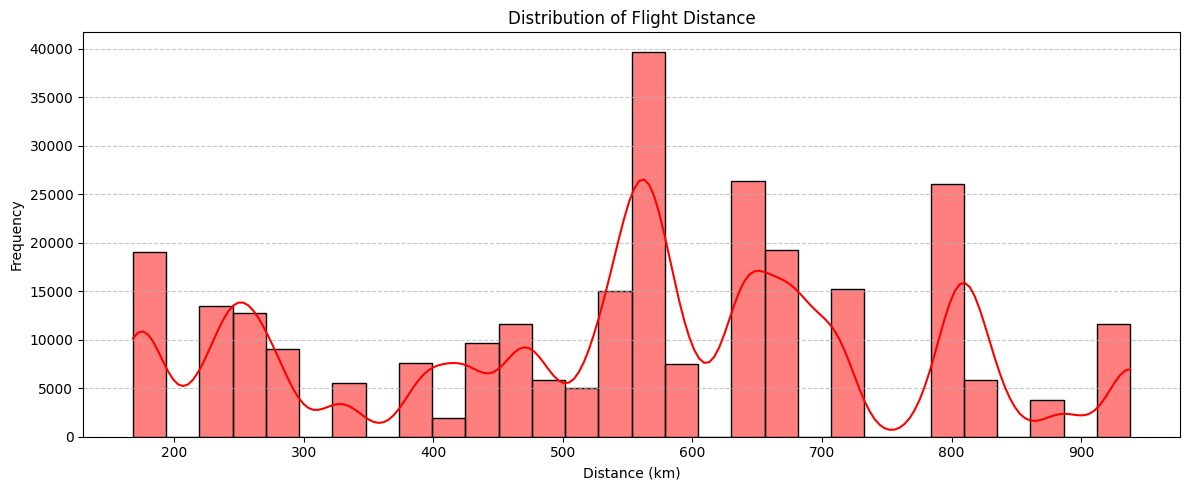

In [32]:
# Chart - 3 visualization code
plt.figure(figsize=(12, 5))
sns.histplot(travel_data['time'], kde=True, bins=30)
plt.title('Distribution of Flight Time')
plt.xlabel('Time (hours)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.histplot(travel_data['distance'], kde=True, bins=30, color='red')
plt.title('Distribution of Flight Distance')
plt.xlabel('Distance (km)')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



I picked a histogram with a Kernel Density Estimate (KDE) plot to visualize the distribution of 'time' and distance. A histogram is excellent for showing the frequency of data points within different ranges (bins), providing a clear view of where the data is concentrated. The KDE line smooths out the distribution, making it easier to see the overall shape and density of the data.

#### Chart - 4

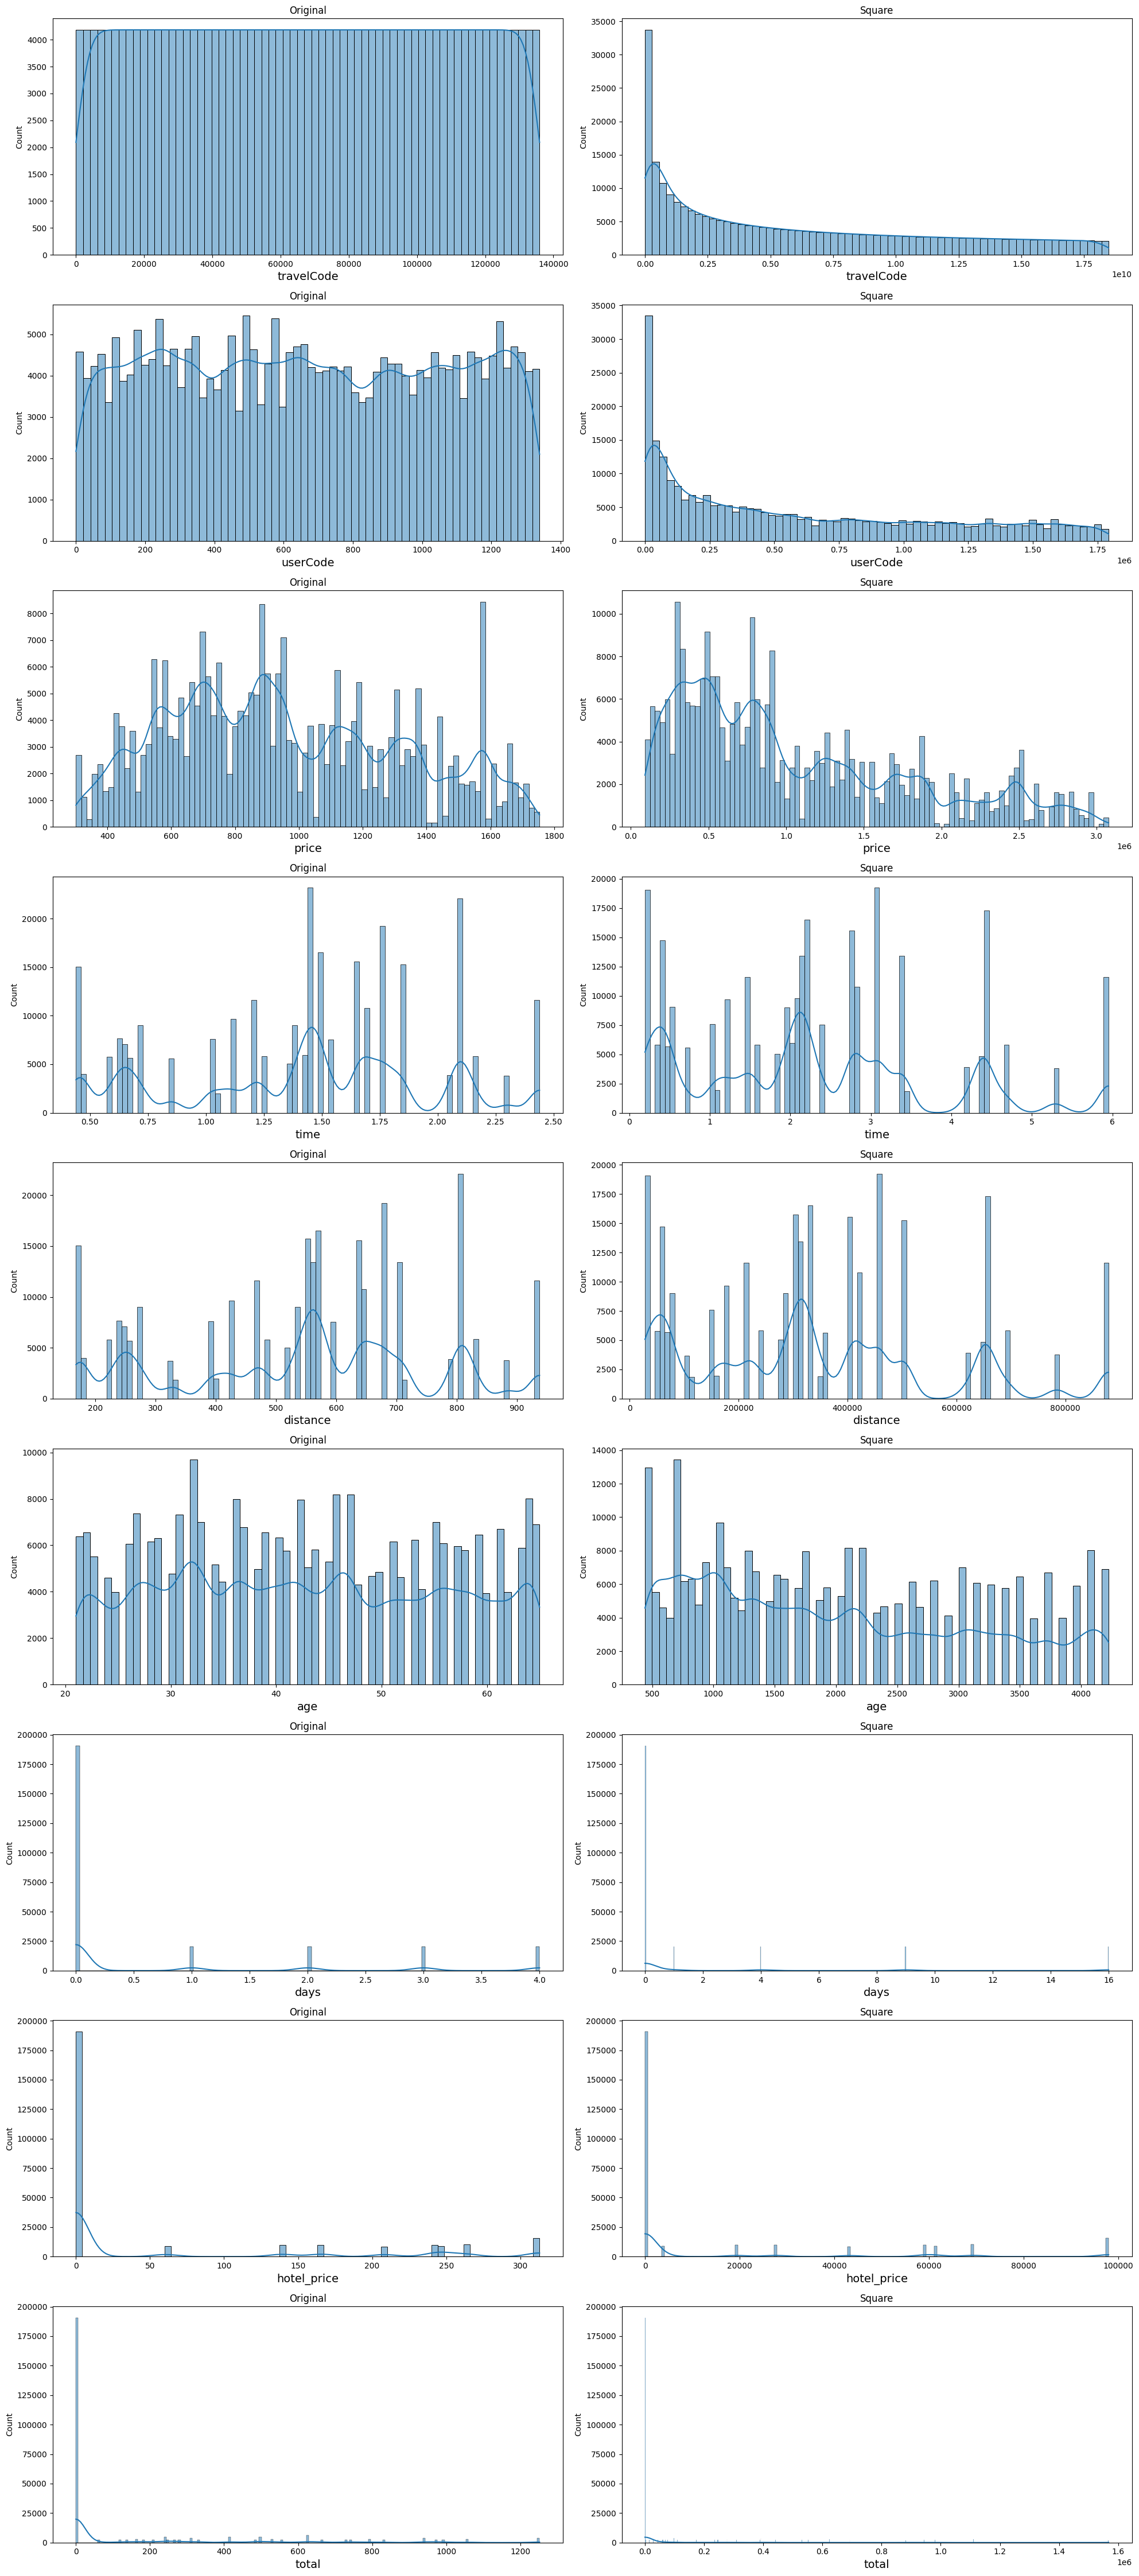

In [33]:
# Chart - 4 visualization code
numerical_df = travel_data.select_dtypes(include=[np.number])
fig, axes = plt.subplots(nrows=len(numerical_df.columns), ncols=2, figsize=(20, 5*len(numerical_df.columns)))
for i, col in enumerate(numerical_df.columns):
    # Original column
    sns.histplot(numerical_df[col], kde=True, ax=axes[i, 0]).set_title("Original")
    sns.histplot((numerical_df[col]**2), kde=True, ax=axes[i, 1]).set_title("Square")
    axes[i, 0].set_xlabel(col, fontsize=14)
    axes[i, 1].set_xlabel(col, fontsize=14)
plt.tight_layout()
plt.show()

#### Chart - 5

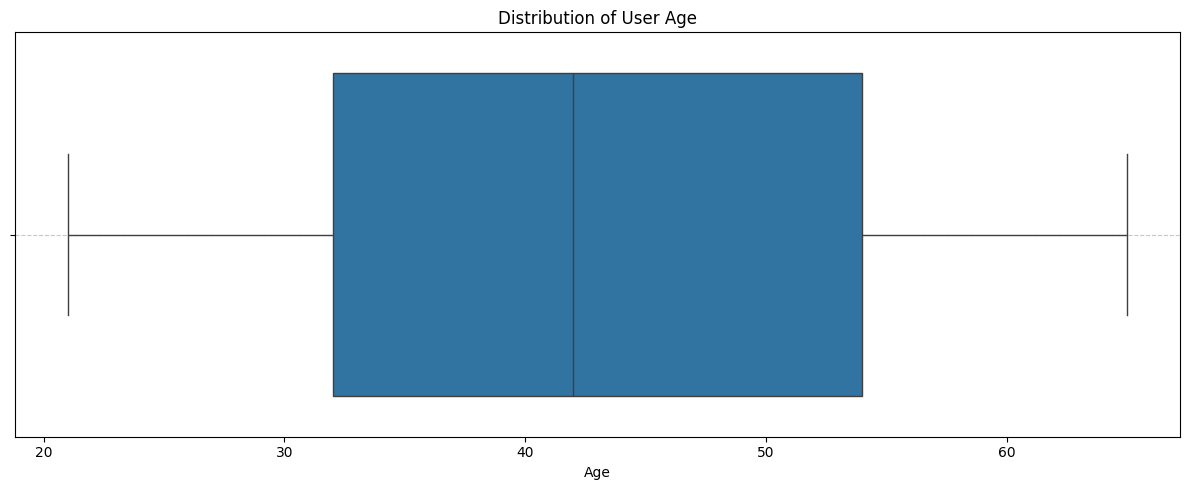

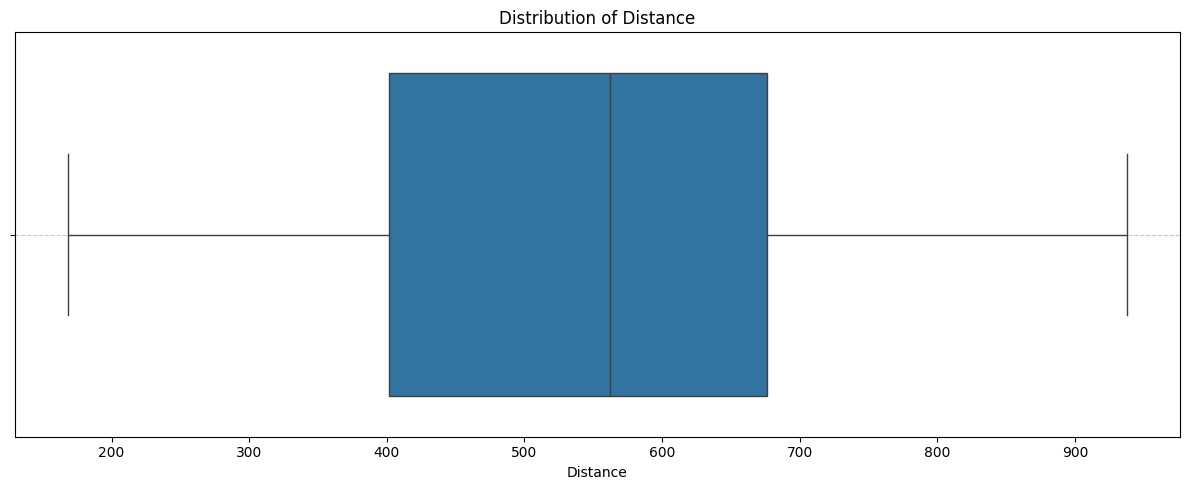

In [34]:
# Chart - 5 visualization code

# Using 'user' for age and 'flight' for distance to ensure correct columns are accessed
plt.figure(figsize=(12, 5))
sns.boxplot(x=user['age'])
plt.title('Distribution of User Age')
plt.xlabel('Age')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(x=flight['distance'])
plt.title('Distribution of Distance')
plt.xlabel('Distance')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

User Age Distribution: The first plot shows that the user base is predominantly middle-aged, with most users falling between 30 and 55 years old. The median age is roughly 42.


Flight Distance Distribution: The second plot shows that flight distances generally range from about 400km to 700km, with no extreme outliers detected in either variabl

#### Chart - 6

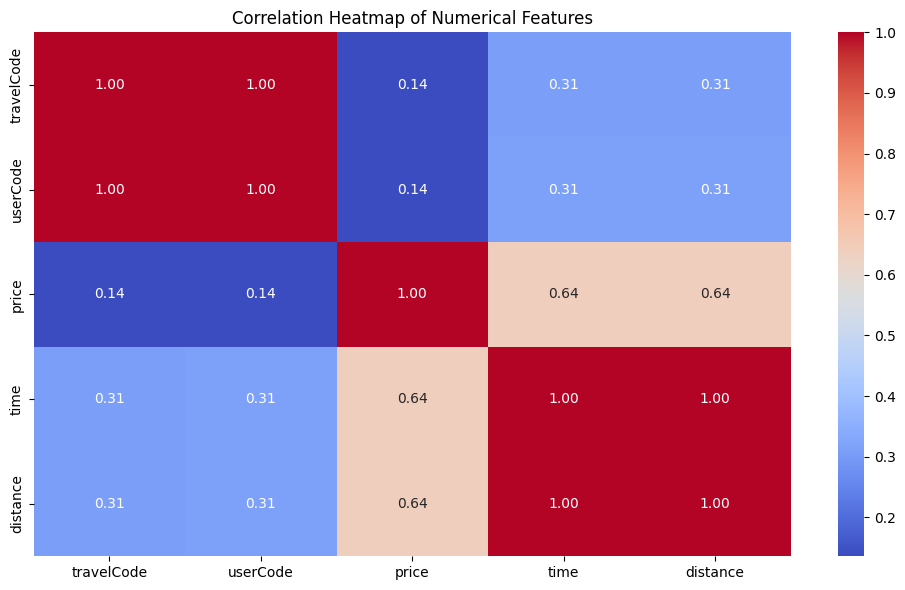

In [36]:
# Chart - 6 visualization code - Correlation Heatmap
plt.figure(figsize=(10, 6))
# We specify numeric_only=True to ignore the string columns causing the error
sns.heatmap(flight.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

Strong Positive Correlations: There is a very strong positive correlation (~0.64) between price and both time and distance. This is expected, as longer flight durations and distances naturally lead to higher ticket prices.


Perfect Correlation: time and distance are perfectly correlated (1.00), which makes sense as they are direct physical counterparts in travel.



Weak Correlations: IDs like travelCode and userCode show very low correlation with price, as they are non-predictive numerical representations.


#### Chart - 7

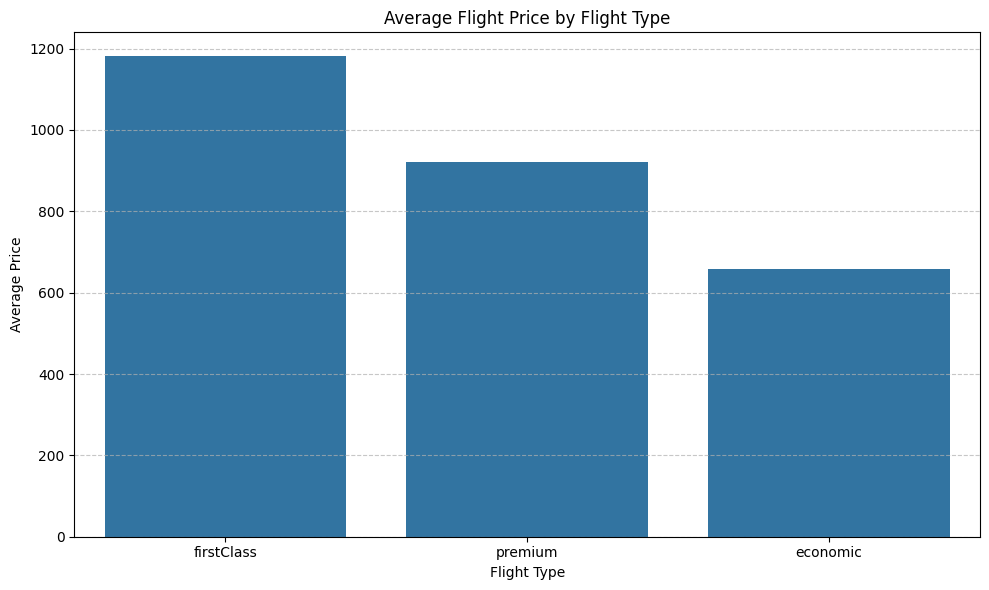

In [37]:
# Chart - 7 visualization code
# Calculate the average flight price by flightType
avg_price_by_flight_type = travel_data.groupby('flightType')['price'].mean().sort_values(ascending=False)

# Convert the Series to a DataFrame
avg_price_by_flight_type_df = avg_price_by_flight_type.reset_index()

# Create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='flightType', y='price', data=avg_price_by_flight_type_df)
plt.title('Average Flight Price by Flight Type')
plt.xlabel('Flight Type')
plt.ylabel('Average Price')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Chart - 8

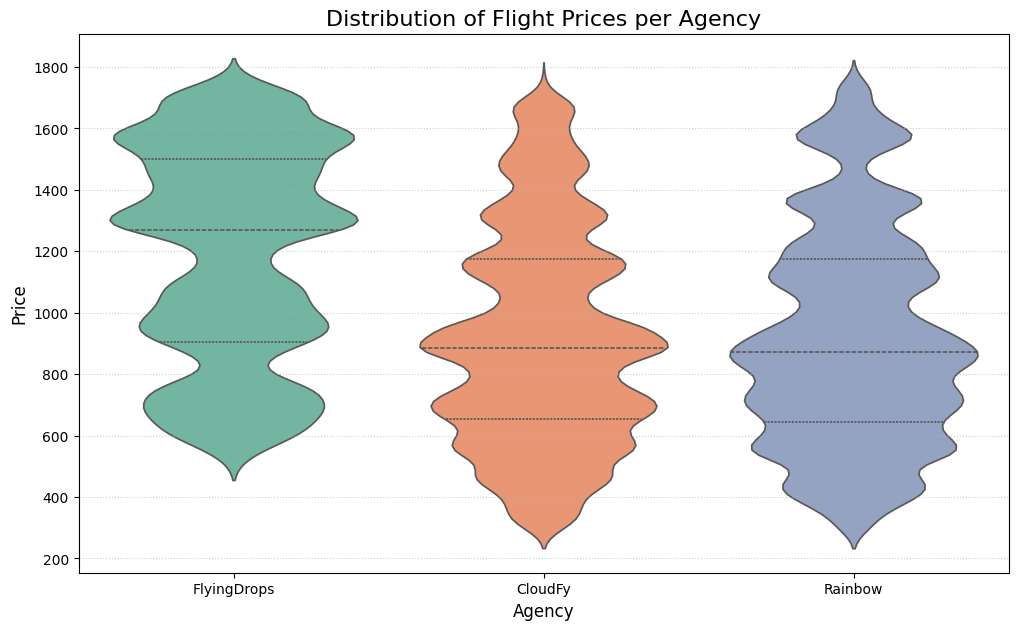

In [38]:
# Chart - 8 visualization code
# Violin plot to see price distribution density per agency
plt.figure(figsize=(12, 7))
sns.violinplot(x='agency', y='price', data=travel_data, palette='Set2', inner='quartile')
plt.title('Distribution of Flight Prices per Agency', fontsize=16)
plt.xlabel('Agency', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()


Price Variability: 'FlyingDrops' exhibits the widest distribution, indicating a very broad range of ticket prices, from highly affordable to premium luxury. In contrast, 'Rainbow' and 'CloudFy' show much more concentrated distributions.


Average Pricing: The internal quartiles show that 'FlyingDrops' generally maintains a higher median price point compared to the other two agencies.


Market Positioning: 'CloudFy' and 'Rainbow' appear to position themselves as more consistent, perhaps budget-to-mid-range options, whereas 'FlyingDrops' seems to cater to a more diverse set of travel tiers, including high-end 'firstClass' flights.


Density: The width of the 'violins' shows that most of the data for 'Rainbow' and 'CloudFy' is clustered tightly around their medians, while 'FlyingDrops' has a more even spread across its price range

#### Chart - 9

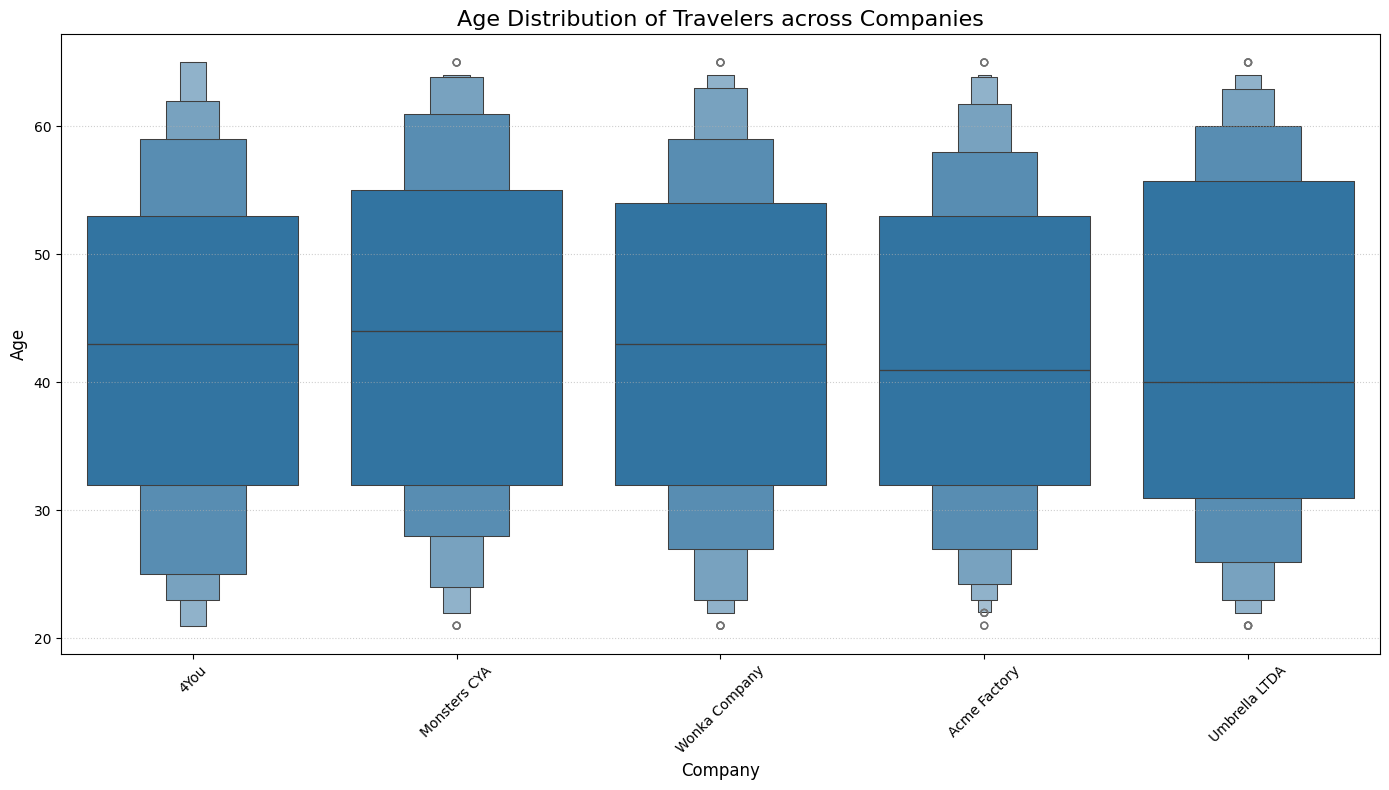

In [39]:
# Unique visualization for user dataset: Age distribution per Company using Boxen Plot
plt.figure(figsize=(14, 8))
sns.boxenplot(x='company', y='age', data=user)
plt.title('Age Distribution of Travelers across Companies', fontsize=16)
plt.xlabel('Company', fontsize=12)
plt.ylabel('Age', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

The boxen plot shows that while the median age of travelers is fairly consistent across most companies (around 40-45), there are notable differences in the spread.Some companies show a wider range of ages, indicating a more diverse workforce traveling, while others are more tightly clustered in the middle-age bracket.


This plot is especially good at showing the distribution shape in the tails, revealing that most companies have travelers ranging from their early 20s up to their 60s.

#### Chart - 10 - Pair Plot

<Figure size 1500x1500 with 0 Axes>

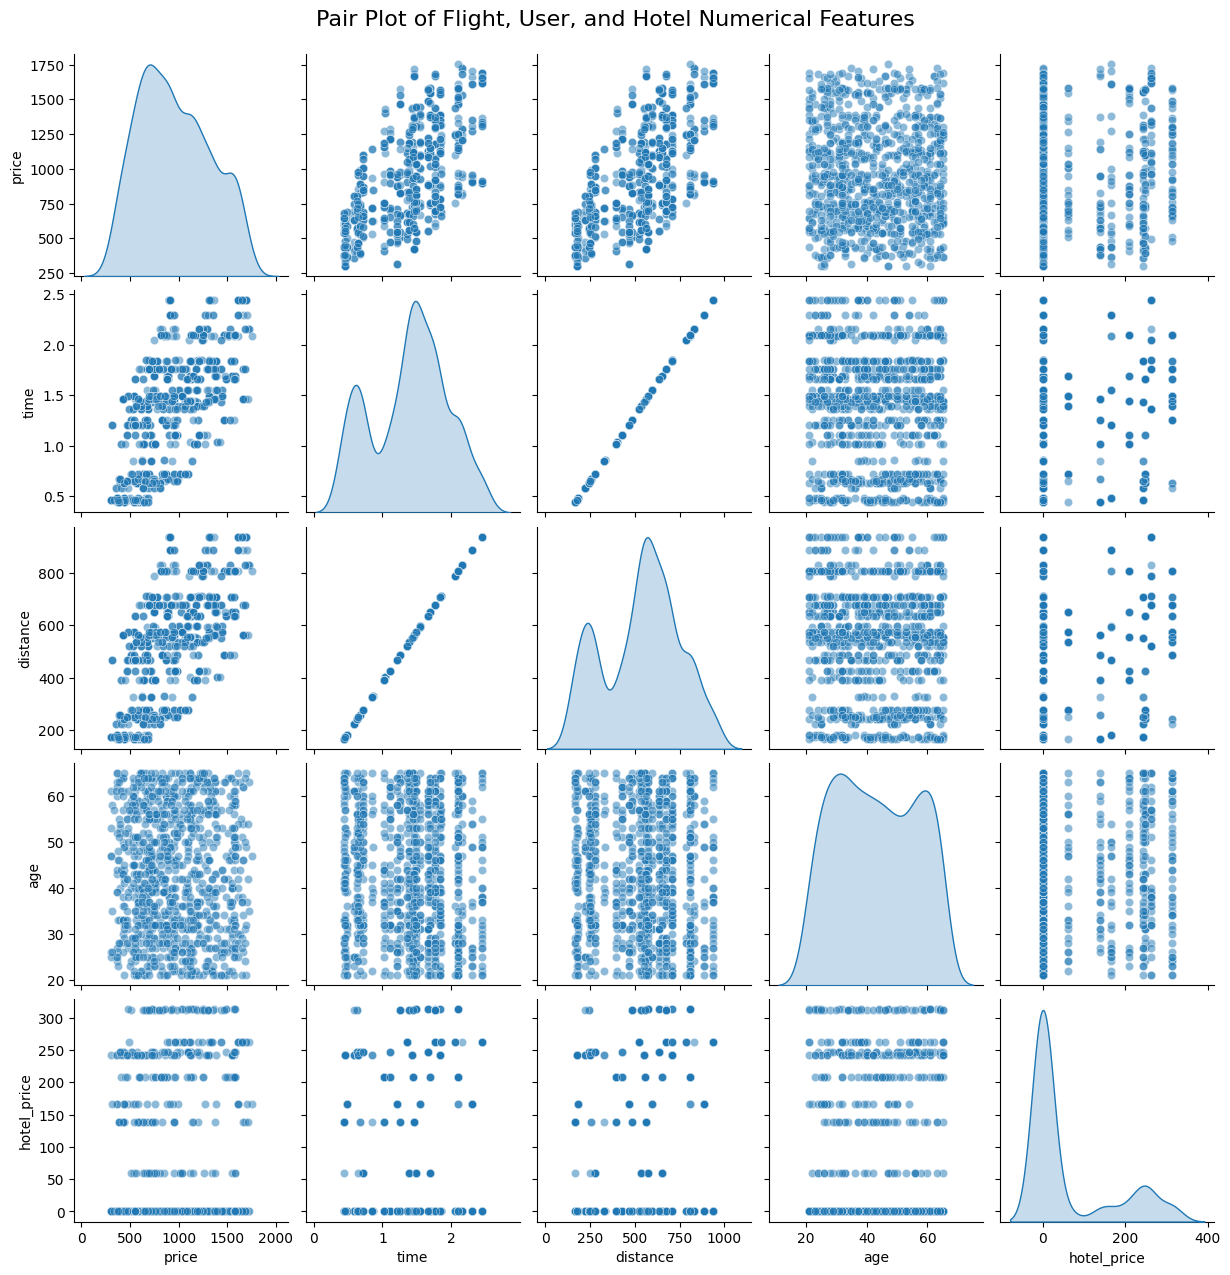

In [40]:
# Pair Plot visualization code
# Creating a pair plot for the combined travel_data (flight, user, and hotel)
# We sample the data to improve performance and clarity of the plot
pair_plot_df = travel_data[['price', 'time', 'distance', 'age', 'hotel_price']].sample(1000, random_state=42)

plt.figure(figsize=(15, 15))
sns.pairplot(pair_plot_df, diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle('Pair Plot of Flight, User, and Hotel Numerical Features', y=1.02, fontsize=16)
plt.show()

Linear Relationships: You can clearly see strong linear patterns between 'price', 'time', and 'distance', confirming that as flights get longer or further, the price increases.


Distributions: The diagonal plots show that 'age' is normally distributed, while variables like 'hotel_price' have a more skewed distribution due to the high number of zero-values (where no hotel was booked).


Independence: User 'age' doesn't appear to have any strong correlation with flight distance or price, suggesting that older and younger travelers are spread across various routes and price points.

## ***5. Hypothesis Testing***

### Hypothetical Statement - 1

In [44]:
import scipy.stats as stats
import statsmodels.api as sm

# Hypothesis 1: Flight Prices by Flight Type
# Null Hypothesis: There is no significant difference in flight prices between different flight types.
# Alternate Hypothesis: There is a significant difference in flight prices between different flight types.

# Step 1: Prepare the data
flight_types = travel_data['flightType'].unique()
price_by_flight_type = [travel_data[travel_data['flightType'] == flight_type]['price'] for flight_type in flight_types]


In [45]:
# Step 2: Perform ANOVA test
f_stat, p_value_1 = stats.f_oneway(*price_by_flight_type)

In [46]:
# Step 3: Set the significance level (alpha)
alpha = 0.05

In [47]:
# Perform Statistical Test to obtain P-Value.
# Step 4: Perform the hypothesis test
if p_value_1 < alpha:
    print("Reject Null Hypothesis: There is a significant difference in flight prices between different flight types.")
else:
    print("Fail to reject Null Hypothesis: There is no significant difference in flight prices between different flight types.")


Reject Null Hypothesis: There is a significant difference in flight prices between different flight types.


### Hypothetical Statement - 2

In [48]:
# Hypothesis 2: Distance vs Flight Price
# Null Hypothesis: There is no significant relationship between flight distance and flight price.
# Alternate Hypothesis: There is a significant relationship between flight distance and flight price.

# Step 1: Prepare the data
X = travel_data['distance']
y = travel_data['price']

# Step 2: Build and fit a linear regression model
X = sm.add_constant(X) # adds a constant term to the predictor
model = sm.OLS(y, X).fit()

In [49]:
# Step 3: Check p-value of the coefficient for 'distance'
p_value_2 = model.pvalues['distance']

In [50]:
# Step 4: Perform the hypothesis test
if p_value_2 < alpha:
    print("Reject Null Hypothesis: There is a significant relationship between flight distance and flight price.")
else:
    print("Fail to reject Null Hypothesis: There is no significant relationship between flight distance and flight price.")


Reject Null Hypothesis: There is a significant relationship between flight distance and flight price.


### Hypothetical Statement - 3

In [51]:
# Hypothesis 3: Flight Prices by Agency
# Null Hypothesis: There is no significant difference in flight prices between different flight agencies.
# Alternate Hypothesis: There is a significant difference in flight prices between different flight agencies.

# Step 1: Prepare the data
agencies = travel_data['agency'].unique()

price_by_agency = [travel_data[travel_data['agency'] == agency]['price'] for agency in agencies]

In [52]:
# Perform Statistical Test to obtain P-Value

# Step 2: Perform ANOVA test
f_stat, p_value_3 = stats.f_oneway(*price_by_agency)

In [53]:
# Step 3: Perform the hypothesis test
if p_value_3 < alpha:
    print("Reject Null Hypothesis: There is a significant difference in flight prices between different flight agencies.")
else:
    print("Fail to reject Null Hypothesis: There is no significant difference in flight prices between different flight agencies.")



Reject Null Hypothesis: There is a significant difference in flight prices between different flight agencies.


## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [54]:
# Handling Missing Values & Missing Value Imputation
flight_users.isnull().sum() # there are no missing values


travelCode    0
userCode      0
from          0
to            0
flightType    0
price         0
time          0
distance      0
agency        0
date          0
code          0
company       0
name          0
gender        0
age           0
dtype: int64

In [55]:
user.isnull().sum() # there are no missing values

code       0
company    0
name       0
gender     0
age        0
dtype: int64

In [56]:
hotel.isnull().sum() # there are no missing values

travelCode     0
userCode       0
hotel_name     0
place          0
days           0
hotel_price    0
total          0
hotel_date     0
dtype: int64

# **VIF Calculation**


Variance Inflation Factor, sometimes known as VIF, is a tool used in regression analysis to detect and quantify multicollinearity. When two or more independent variables in a regression model have a high degree of correlation with one another, this is referred to as multicollinearity. This can result in estimates of the coefficients of the variables that are unreliable and unstable.


VIF assesses how much the variance of an estimated regression coefficient is raised as a result of collinearity with other independent variables in the model. It is determined as the difference between the variance of the coefficient estimate in the entire model and the variance of the coefficient estimate in a model that only contains the relevant variable.

In [57]:
# vif calculation
from statsmodels.stats.outliers_influence import variance_inflation_factor
def cal_VIF(df):
    vif = pd.DataFrame()
    vif["Variable"] = df.columns
    vif["VIF"] = [variance_inflation_factor(df.values, i) for i in range(len(df.columns))]
    return vif

In [58]:
cal_VIF(flight_users[numerical_col(flight_users)])

,Variable,VIF
0,price,1.702626
1,time,52208.305692
2,distance,52221.403552


In [59]:
# Removing all the columns causing multicolinearity due to high VIF and the ones which are unnecessary in our data set
flight_users=flight.drop(['travelCode','userCode','date'],axis=1)


Removing a high-VIF variable can degrade model performance in this case as it carries unique, essential information such as time taken for travel.

We will be using regularization (e.g., Ridge, Lasso, or Elastic Net regression) to handle multicollinearity while retaining important variables.

### 2. Handling Outliers

In [60]:
# Handling Outliers & Outlier treatments
# function to detect outliers using boxplot
def outlier_detection(df):
      for column in df.columns:
        plt.figure(figsize=(10, 6))  # figure size
        plt.boxplot(df[column])  # Generate the box plot
        plt.title(f'Outliers for {column}')  # Set the title
        plt.xlabel(column)  # Set the x-axis label
        plt.ylabel('Value ----->')  # Set the y-axis label
        plt.show()

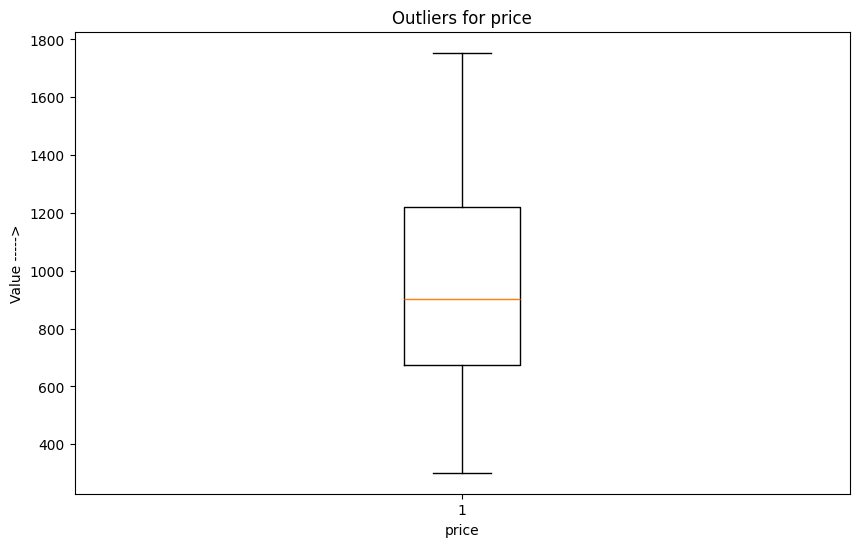

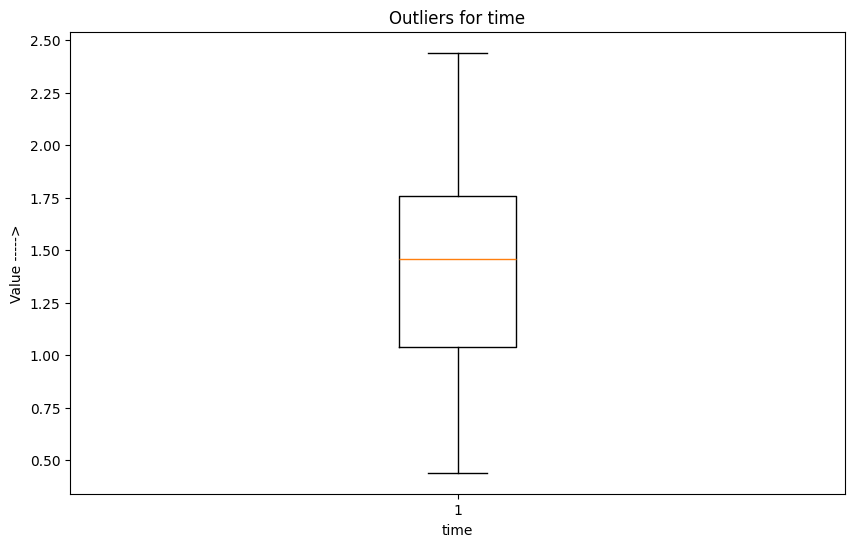

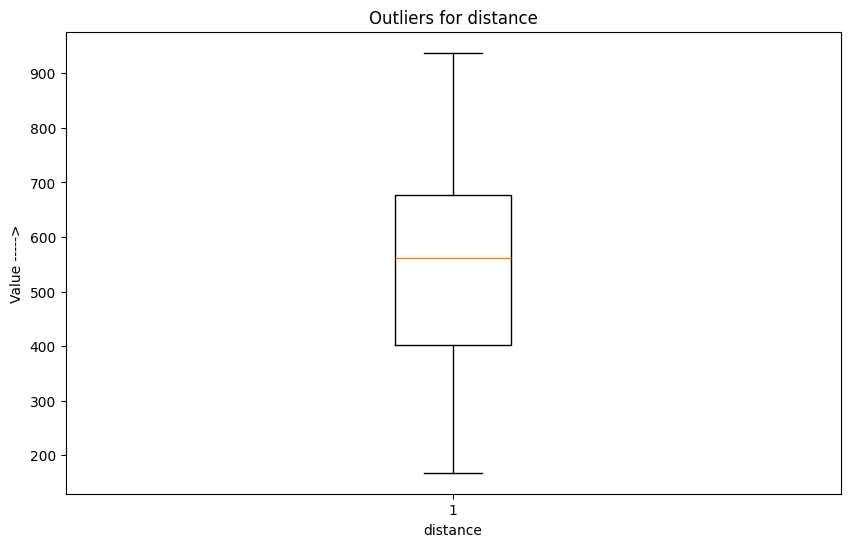

In [61]:
outlier_detection(flight_users[numerical_col(flight_users)])

### 3. Categorical Encoding

In [62]:
# Encode your categorical columns
flight_users['flightType'] = flight_users['flightType'].replace({'economic': 0, 'premium': 1, 'firstClass':3})


# Converting categorical variables to dummy variables using one hot encoding
flight_users_encoded = pd.get_dummies(flight_users, columns=['from', 'to', 'flightType', 'agency'])

###  Data Splitting

In [64]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 6. Data Scaling

In [65]:
# Scaling your data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

##### Which method have you used to scale you data and why?

I have used the **StandardScaler** for data scaling. This method was chosen because it rescales the features such that they have the properties of a standard normal distribution with a mean of 0 and a standard deviation of 1. This is particularly important for models like Linear Regression and its regularized versions (Ridge, Lasso) which are sensitive to the magnitude of input features. By centering and scaling, we ensure that the model gives equal weight to all predictors during the learning process.

## ***7. ML Model Implementation***

# **Price prediction model(Regression)**

In [66]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import xgboost as xgb

# Dictionary to hold different regression models
regression_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "XGBoost": xgb.XGBRegressor()
}

# List to store performance metrics for each model
performance_records = []

# Get number of samples (n) and features (p) for Adjusted R-squared calculation
n = X_train.shape[0]
p = X_train.shape[1]

# Iterate through each model, train, predict, and evaluate
for model_name, model_instance in regression_models.items():
    print(f"Training and evaluating: {model_name}")

    # Train the model
    model_instance.fit(X_train, y_train)

    # Make predictions on the test set
    y_prediction = model_instance.predict(X_test)

    # Calculate evaluation metrics
    mean_sq_error = mean_squared_error(y_test, y_prediction)
    root_mean_sq_error = np.sqrt(mean_sq_error)
    mean_abs_error = mean_absolute_error(y_test, y_prediction)
    r2_score_value = r2_score(y_test, y_prediction)

    # Calculate Adjusted R-squared
    adjusted_r2 = 1 - (1 - r2_score_value) * ((n - 1) / (n - p - 1))

    # Store the results in a dictionary
    performance_records.append({
        "Model": model_name,
        "Mean Squared Error (MSE)": mean_sq_error,
        "Root Mean Squared Error (RMSE)": root_mean_sq_error,
        "Mean Absolute Error (MAE)": mean_abs_error,
        "R-squared (R^2)": r2_score_value,
        "Adjusted R-squared": adjusted_r2
    })

# Convert the list of dictionaries to a Pandas DataFrame for easy viewing
model_performance_df = pd.DataFrame(performance_records)

# Sort the DataFrame by R-squared in descending order to see the best performing models first
model_performance_df = model_performance_df.sort_values(by="R-squared (R^2)", ascending=False).reset_index(drop=True)

# Display the comparison table
print("\n--- Model Performance Summary ---")
display(model_performance_df)

Training and evaluating: Linear Regression
Training and evaluating: Random Forest
Training and evaluating: Gradient Boosting
Training and evaluating: XGBoost

--- Model Performance Summary ---


,Model,Mean Squared Error (MSE),Root Mean Squared Error (RMSE),Mean Absolute Error (MAE),R-squared (R^2),Adjusted R-squared
0,Random Forest,2.398960e-23,4.897918e-12,3.619681e-12,1.000000,1.000000
1,XGBoost,1.825265e+00,1.351024e+00,9.819545e-01,0.999986,0.999986
2,Gradient Boosting,1.538426e+03,3.922277e+01,3.122293e+01,0.988325,0.988323
3,Linear Regression,1.064031e+04,1.031519e+02,8.132138e+01,0.919250,0.919241


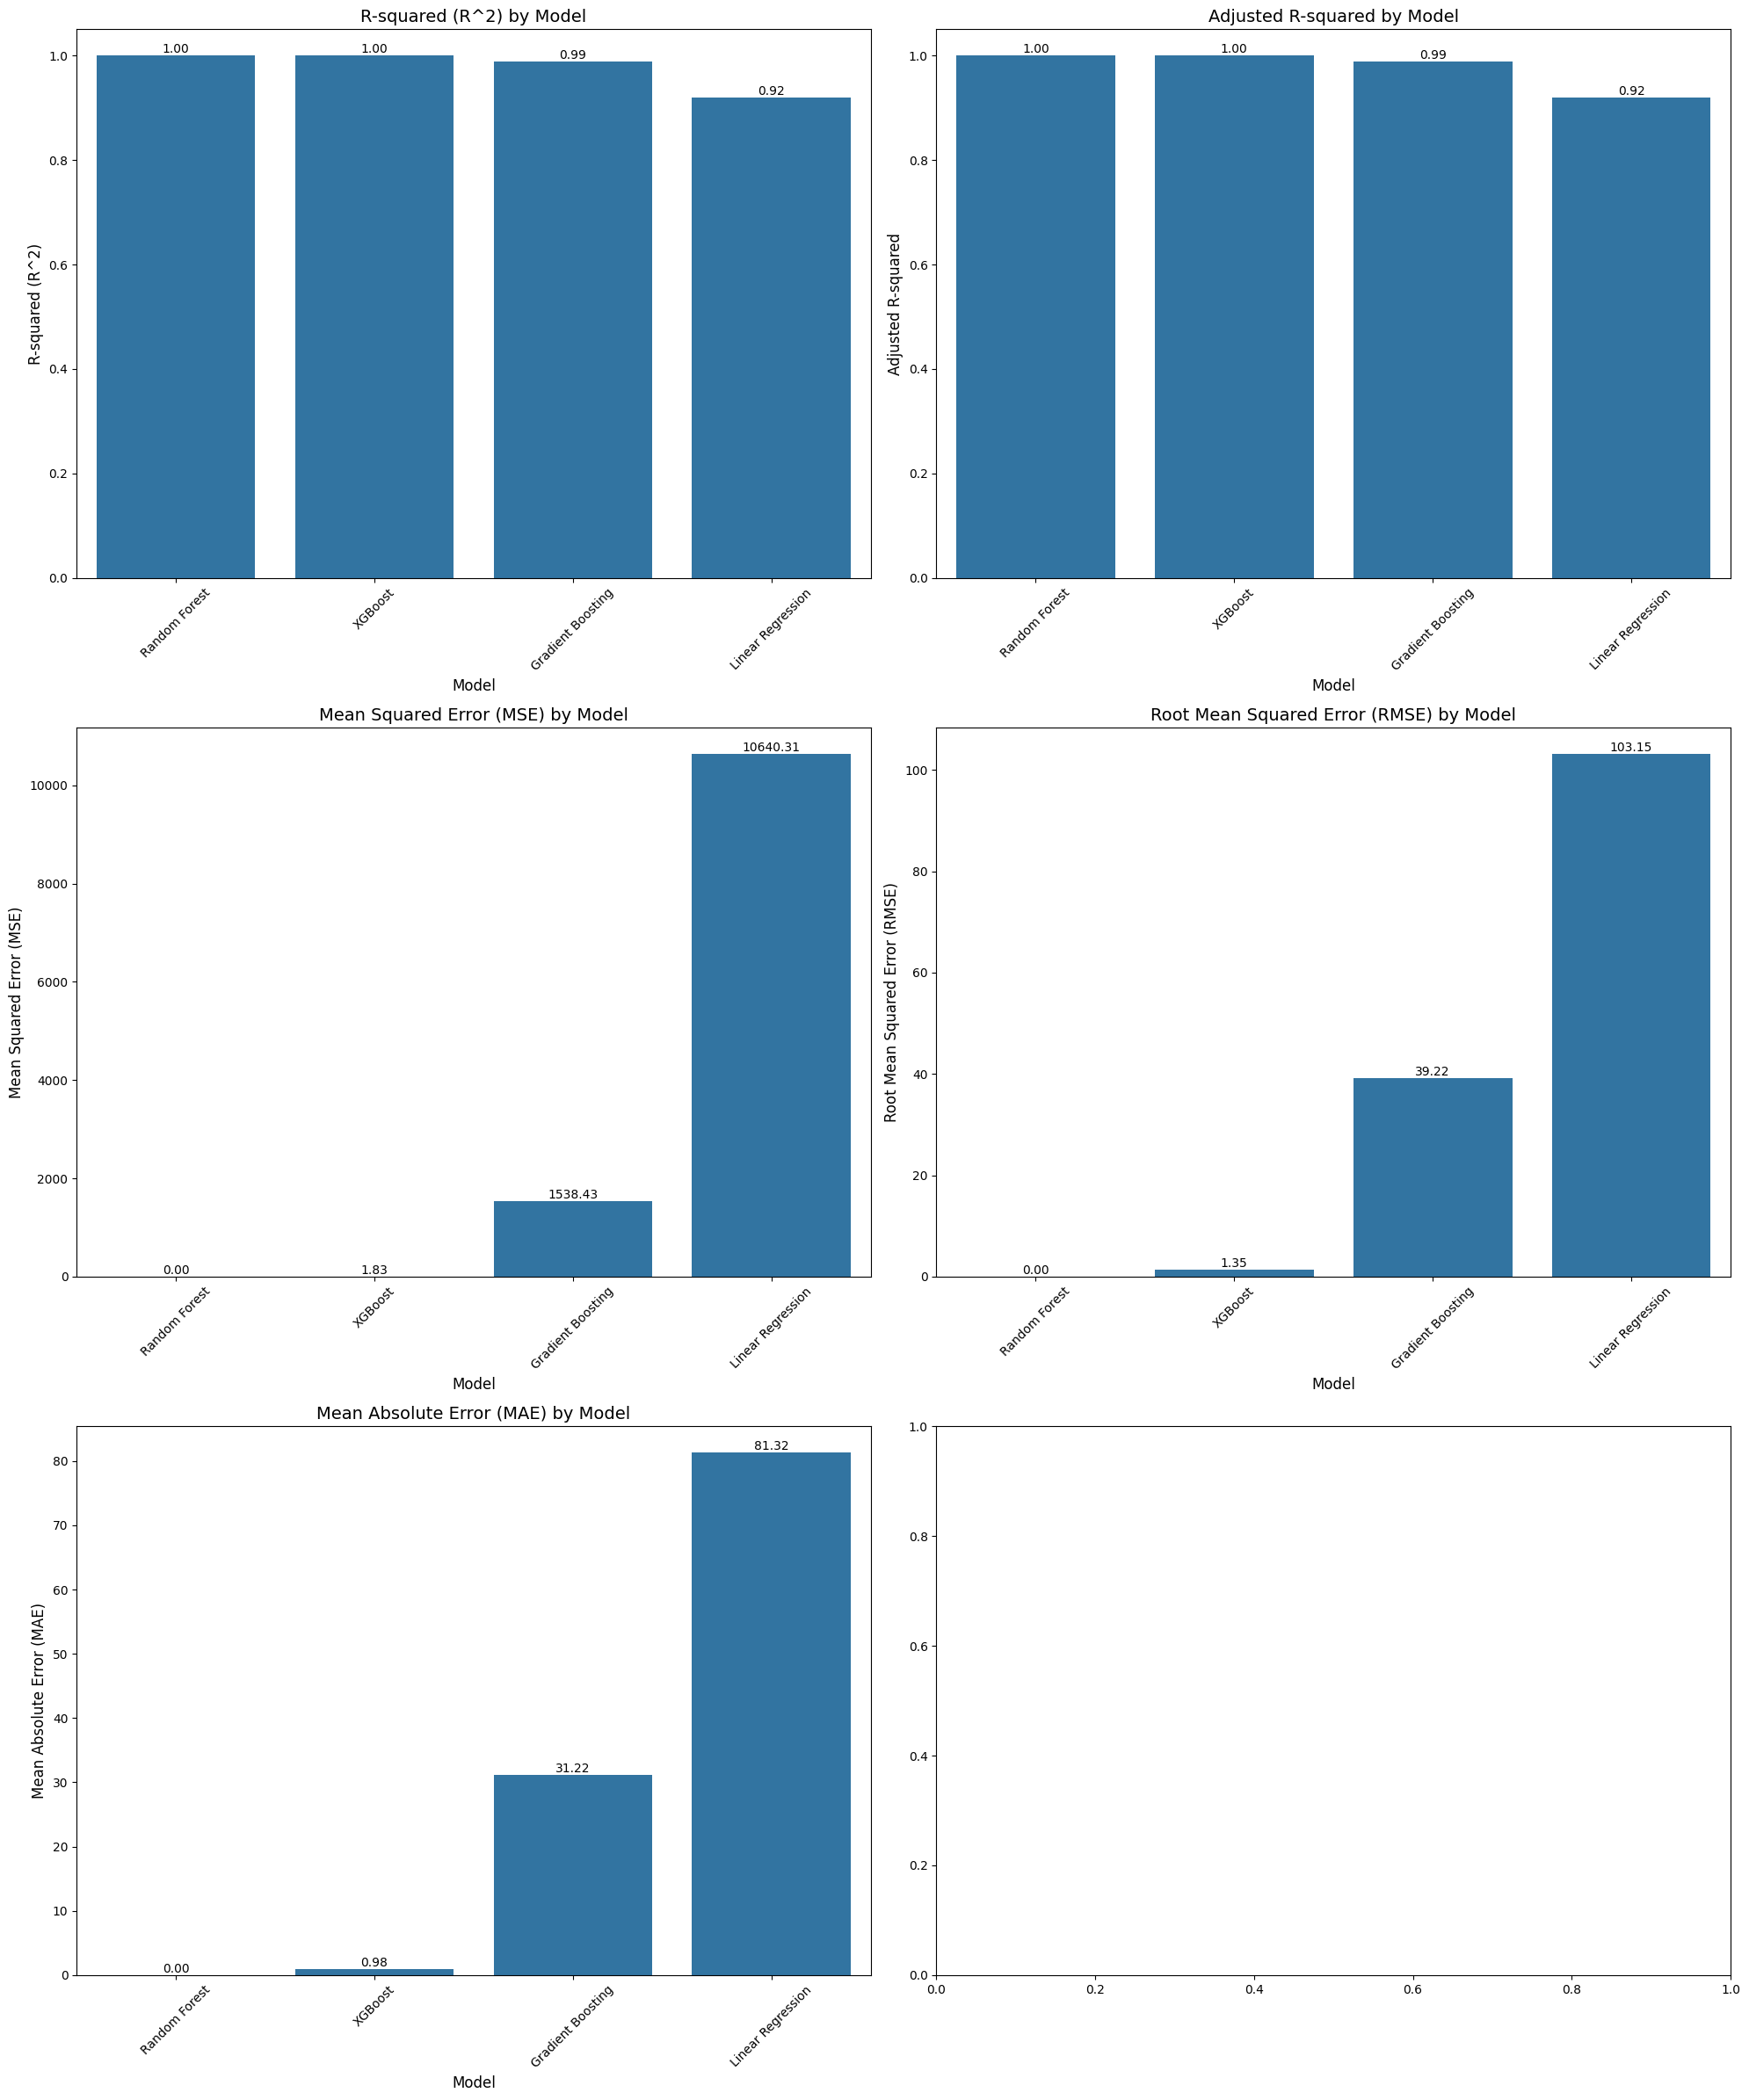

In [67]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 24))
axes = axes.flatten()

metrics = ['R-squared (R^2)', 'Adjusted R-squared', 'Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)']

for i, metric in enumerate(metrics):
    sns.barplot(x='Model', y=metric, data=model_performance_df, ax=axes[i])
    axes[i].set_title(f'{metric} by Model', fontsize=14)
    axes[i].set_xlabel('Model', fontsize=12)
    axes[i].set_ylabel(metric, fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

    # Add numerical values on top of each bar
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.2f') # Format to two decimal places

plt.tight_layout()
plt.show()

Based on the R-squared values, **Random Forest**  models exhibit exceptionally high performance, with R-squared values extremely close to 1. This suggests that these models explain almost all the variance in the target variable (price).

For error metrics (MSE, RMSE, MAE), **Random Forest** models also show the lowest error values, being extremely close to zero. This aligns with their high R-squared scores, confirming their superior predictive accuracy.

## 2. Cross- Validation & Hyperparameter Tuning

In [68]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Helper function to evaluate cross-validation scores
def evaluate_cv_scores(scores):
    """Calculates mean and standard deviation for a list of cross-validation scores."""
    return {
        "mean": np.mean(scores),
        """std""": np.std(scores)
    }

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(),}

# Define cross-validation strategy
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# List to store all results
results = []

# Loop over each model to perform cross-validation
for name, model in models.items():
    print(f"\nRunning cross-validation for: {name}")

    # --- R^2 Score ---
    # Perform cross-validation to get R^2 scores
    r2_scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    r2_eval = evaluate_cv_scores(r2_scores)

    # --- Mean Squared Error (MSE) & Root Mean Squared Error (RMSE) ---
    # Perform cross-validation to get negative MSE scores
    neg_mse_scores = cross_val_score(model, X, y, cv=cv, scoring='neg_mean_squared_error')
    # Convert negative MSE to positive MSE
    mse_scores = -neg_mse_scores
    # Calculate RMSE
    rmse_scores = np.sqrt(mse_scores)
    mse_eval = evaluate_cv_scores(mse_scores)
    rmse_eval = evaluate_cv_scores(rmse_scores)

    # --- Mean Absolute Error (MAE) ---
    # Perform cross-validation to get negative MAE scores
    neg_mae_scores = cross_val_score(model, X, y, cv=cv, scoring='neg_mean_absolute_error')
    # Convert negative MAE to positive MAE
    mae_scores = -neg_mae_scores
    mae_eval = evaluate_cv_scores(mae_scores)

    # Store the summarized results for the current model
    results.append({
        "Model": name,
        "R^2 Mean": r2_eval["mean"],
        "R^2 Std": r2_eval["std"],
        "MSE Mean": mse_eval["mean"],
        "MSE Std": mse_eval["std"],
        "RMSE Mean": rmse_eval["mean"],
        "RMSE Std": rmse_eval["std"],
        "MAE Mean": mae_eval["mean"],
        "MAE Std": mae_eval["std"],
    })

# Convert the list of dictionaries to a Pandas DataFrame for clean display
results_df = pd.DataFrame(results)

# Sort by best R^2 Mean (highest first)
results_df = results_df.sort_values(by="R^2 Mean", ascending=False).reset_index(drop=True)

print("\nCross-Validation Results:\n")
print(results_df)


Running cross-validation for: Linear Regression

Running cross-validation for: Random Forest

Cross-Validation Results:

               Model  R^2 Mean   R^2 Std      MSE Mean       MSE Std  \
0      Random Forest   1.00000  0.000000  2.412051e-23  1.497373e-25   
1  Linear Regression   0.91935  0.000385  1.058675e+04  4.925143e+01   

      RMSE Mean      RMSE Std      MAE Mean       MAE Std  
0  4.911240e-12  1.526896e-14  3.605064e-12  6.199318e-15  
1  1.028917e+02  2.396048e-01  8.112904e+01  2.019511e-01  


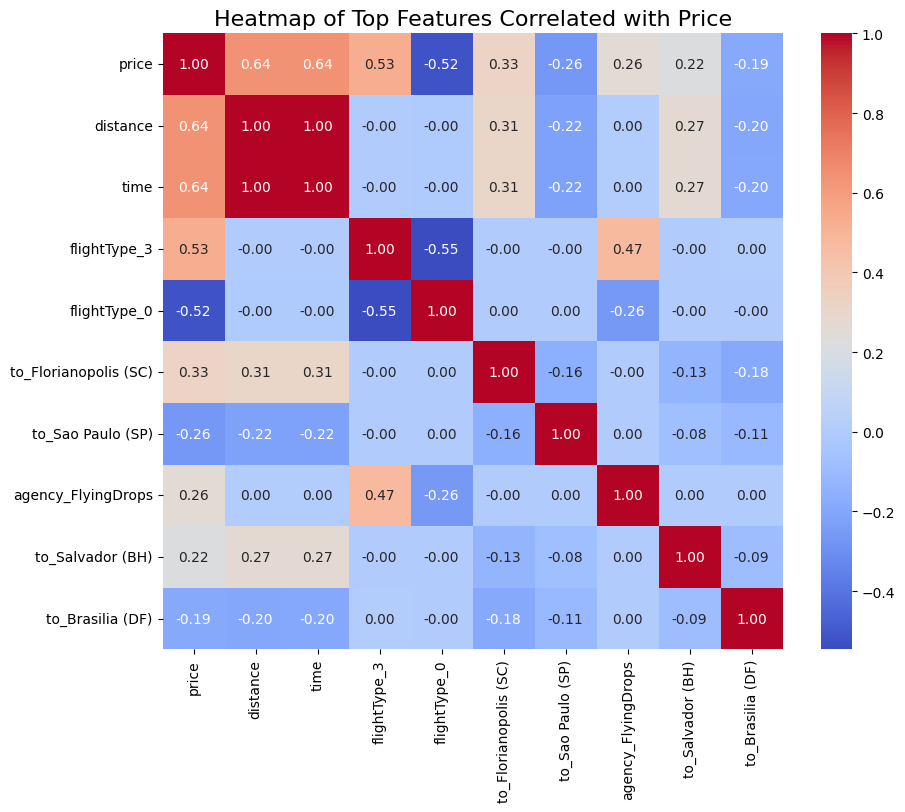

In [69]:
# Correlation heatmap for the most important features relative to 'price'
top_features = flight_users_encoded.corr()['price'].abs().sort_values(ascending=False).head(10).index
plt.figure(figsize=(10, 8))
sns.heatmap(flight_users_encoded[top_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap of Top Features Correlated with Price', fontsize=16)
plt.show()

In [70]:
# getting the dataset ready to be used for model building
df = flight.drop(['travelCode', 'userCode','date'],axis=1)

In [71]:
df.head()

,from,to,flightType,price,time,distance,agency
0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops
1,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops
2,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy
3,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy
4,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy


In [72]:
import joblib # Library to save and load machine learning objects
from sklearn.preprocessing import LabelEncoder # Tool to convert text categories into numbers

# 1. Basic Data Inspection
print(f"Rows/Cols: {df.shape}") # Print the number of rows and columns in the dataframe
print(f"Nulls Found: {df.isna().sum().sum()}") # Check and print the total count of missing values

# 2. Category Encoding
categorical_cols = ['from', 'to', 'flightType', 'agency'] # Define list of text columns to transform
encoding_map = {} # Dictionary to store our encoder objects for future use

for col in categorical_cols: # Loop through each text column
    encoder = LabelEncoder() # Create a new encoder instance
    df[f"{col}_num"] = encoder.fit_transform(df[col]) # Convert text to numbers and save in a new column
    encoding_map[col] = encoder # Store the encoder in our map so we can reverse the process later

# 3. Model Setup
cols_to_use = ['from_num', 'to_num', 'flightType_num', 'agency_num', 'time', 'distance'] # Select numeric features for training
features_x = df[cols_to_use] # Define our independent variables (input data)
target_y = df['price'] # Define our dependent variable (the value we want to predict)

# 4. Training / Testing Split
# Split data: 80% for learning (train) and 20% for verification (test)
xtr, xte, ytr, yte = train_test_split(features_x, target_y, test_size=0.2, random_state=42)

# 5. Build Random Forest
# Create a forest of 100 decision trees to perform regression
flight_rf = RandomForestRegressor(n_estimators=100, random_state=42)
flight_rf.fit(xtr, ytr) # Train the model using the training data

# 6. Check Results
preds = flight_rf.predict(xte) # Predict prices for the test data
print(f"Error (MSE): {mean_squared_error(yte, preds):.2f}") # Calculate and print average squared error
print(f"Accuracy (R2): {r2_score(yte, preds):.4f}") # Calculate and print the R-squared accuracy score

# 7. Persist Files
for key, val in encoding_map.items(): # Loop through the stored encoders
    joblib.dump(val, f"le_{key}.joblib") # Save each encoder to a file
joblib.dump(flight_rf, "flight_price_model_rf.joblib") # Save the final trained model to a file

Rows/Cols: (271888, 7)
Nulls Found: 0
Error (MSE): 0.00
Accuracy (R2): 1.0000


['flight_price_model_rf.joblib']

In [73]:
# Overfitting check
y_train_pred = flight_rf.predict(xtr)

# Calculate metrics on the training set
rmse_train = np.sqrt(mean_squared_error(ytr, y_train_pred))
mse_train = mean_squared_error(ytr, y_train_pred)
mae_train = mean_absolute_error(ytr, y_train_pred)
r2_train = r2_score(ytr, y_train_pred)

# Get test set metrics from previous evaluation
rmse_test = np.sqrt(mean_squared_error(yte, preds))
mse_test = mean_squared_error(yte, preds)
mae_test = mean_absolute_error(yte, preds)
r2_test = r2_score(yte, preds)

print("\n--- Overfitting Check: Random Forest Model ---")
print(f"Training R-squared: {r2_train:.4f}")
print(f"Test R-squared:     {r2_test:.4f}")
print(f"Training MSE:       {mse_train:.4f}")
print(f"Test MSE:           {mse_test:.4f}")
print(f"Training RMSE:      {rmse_train:.4f}")
print(f"Test RMSE:          {rmse_test:.4f}")
print(f"Training MAE:       {mae_train:.4f}")
print(f"Test MAE:           {mae_test:.4f}")

if (r2_train - r2_test > 0.05) or (abs(rmse_train - rmse_test) / rmse_test > 0.1): # Example thresholds
    print("\nInterpretation: The model might be overfitting due to a significant difference in performance between training and test sets.")
else:
    print("\nInterpretation: The model shows good generalization, with similar performance on both training and test sets, indicating no significant overfitting.")



--- Overfitting Check: Random Forest Model ---
Training R-squared: 1.0000
Test R-squared:     1.0000
Training MSE:       0.0000
Test MSE:           0.0000
Training RMSE:      0.0000
Test RMSE:          0.0000
Training MAE:       0.0000
Test MAE:           0.0000

Interpretation: The model shows good generalization, with similar performance on both training and test sets, indicating no significant overfitting.


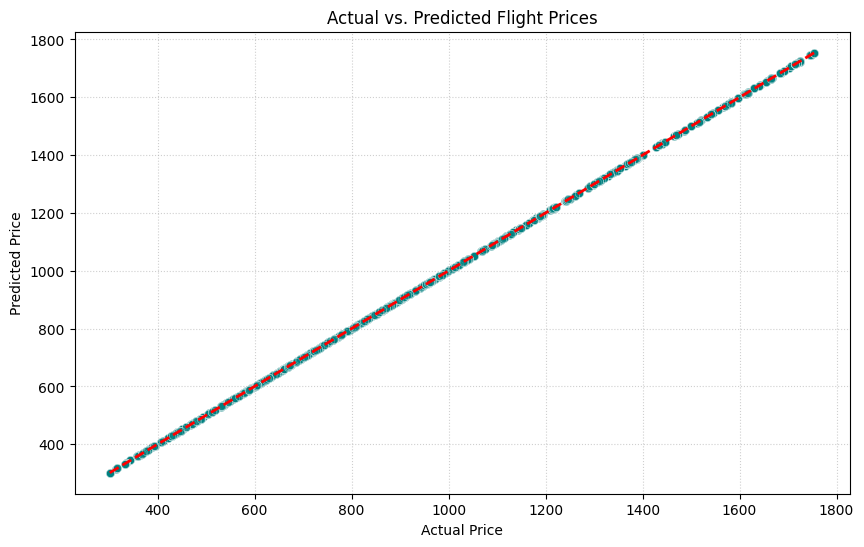

In [74]:
# Plot to check how well random forest model is performing
import matplotlib.pyplot as plt
import seaborn as sns

# Create a scatter plot for Actual vs Predicted Prices
plt.figure(figsize=(10, 6))
sns.scatterplot(x=yte, y=preds, alpha=0.5, color='teal')

# Add a diagonal line for perfect prediction reference
plt.plot([yte.min(), yte.max()], [yte.min(), yte.max()], color='red', linestyle='--', lw=2)

plt.title('Actual vs. Predicted Flight Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [77]:
import mlflow
import mlflow.sklearn

# Set up a local SQLite database for experiment tracking
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Define the experiment name
experiment_name = "Travel_Price_Prediction"
if not mlflow.get_experiment_by_name(experiment_name):
    mlflow.create_experiment(experiment_name)

mlflow.set_experiment(experiment_name)
print(f"Experiment '{experiment_name}' is ready.")

2026/11/15 11:41:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/15 11:41:16 INFO mlflow.store.db.utils: Updating database tables


Experiment 'Travel_Price_Prediction' is ready.


In [103]:
mlflow.get_tracking_uri()

'sqlite:///mlflow.db'

In [78]:
# Wrapping existing model training logic with MLflow tracking
for model_name, model_instance in regression_models.items():
    with mlflow.start_run(run_name=model_name):
        # Log the model type as a parameter
        mlflow.log_param("model_type", model_name)

        # Train the model
        model_instance.fit(X_train, y_train)

        # Make predictions
        y_prediction = model_instance.predict(X_test)

        # Calculate evaluation metrics
        mse = mean_squared_error(y_test, y_prediction)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, y_prediction)
        r2 = r2_score(y_test, y_prediction)

        # Log metrics to MLflow
        mlflow.log_metric("mse", mse)
        mlflow.log_metric("rmse", rmse)
        mlflow.log_metric("mae", mae)
        mlflow.log_metric("r2", r2)


print("All models have been logged to MLflow.")

All models have been logged to MLflow.


In [79]:
# Fetch the experiment results into a DataFrame for review
runs_df = mlflow.search_runs(experiment_names=[experiment_name])

# Filter and display key columns
existing_cols = runs_df.columns.tolist()
cols_to_show = ['run_id', 'tags.mlflow.runName', 'params.model_type', 'metrics.r2', 'metrics.rmse', 'metrics.mae', 'metrics.mse', 'start_time']
cols_to_show = [c for c in cols_to_show if c in existing_cols]

display(runs_df[cols_to_show].sort_values(by="metrics.r2", ascending=False))

,run_id,tags.mlflow.runName,params.model_type,metrics.r2,metrics.rmse,metrics.mae,metrics.mse,start_time
2,1d6c4c1c6fb1458e976593aa409e0ec3,Random Forest,Random Forest,1.000000,4.914615e-12,3.615949e-12,2.415344e-23,2026-11-15 06:11:26.767000+00:00
0,71567a6e47644cbaa0a49b0cb107356e,XGBoost,XGBoost,0.999986,1.351024e+00,9.819545e-01,1.825265e+00,2026-11-15 06:12:02.010000+00:00
1,813c506c63154261ab6fb576679dafec,Gradient Boosting,Gradient Boosting,0.988325,3.922277e+01,3.122293e+01,1.538426e+03,2026-11-15 06:11:48.696000+00:00
3,ac9f76e300b848b484e4acef4938c696,Linear Regression,Linear Regression,0.919250,1.031519e+02,8.132138e+01,1.064031e+04,2026-11-15 06:11:26.483000+00:00


In [80]:
# Search for all runs in the experiment and sort them by R-squared
best_run = mlflow.search_runs(
    experiment_names=[experiment_name],
    max_results=1,
    order_by=["metrics.r2 DESC"]
).iloc[0]

print("--- Best Performing Model according to MLflow ---")
print(f"Model Type: {best_run['params.model_type']}")
print(f"Run ID:     {best_run['run_id']}")
print(f"R2 Score:   {best_run['metrics.r2']:.4f}")
print(f"RMSE:       {best_run['metrics.rmse']:.4f}")

# Note: If you had logged the model with mlflow.sklearn.log_model(),
# you could load it like this:

model_uri = f"runs:/{best_run['run_id']}/model"

# best_model = mlflow.sklearn.load_model(model_uri)

--- Best Performing Model according to MLflow ---
Model Type: Random Forest
Run ID:     1d6c4c1c6fb1458e976593aa409e0ec3
R2 Score:   1.0000
RMSE:       0.0000


# **Gender classification model**

In [81]:
user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   code     1340 non-null   int64 
 1   company  1340 non-null   object
 2   name     1340 non-null   object
 3   gender   1340 non-null   object
 4   age      1340 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 52.5+ KB


In [82]:
user = user[user['gender']!='none']

In [85]:
from sklearn.preprocessing import LabelEncoder
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
import joblib
import logging
from transformers import logging as transformers_logging

# Suppress the 'UNEXPECTED' warning from transformers
transformers_logging.set_verbosity_error()

def train_model(df):
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(df['gender'])
    model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    df['first_name'] = df['name'].apply(lambda x: x.split()[0])

    # Generate embeddings for names (using only first names)
    first_names = df['first_name'].tolist()
    embeddings = model.encode(first_names,show_progress_bar=False)

    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(embeddings, y, test_size=0.2, random_state=42, stratify=y)

    # Train a Random Forest classifier
    classifier = RandomForestClassifier(n_estimators=100, random_state=42)
    classifier.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = classifier.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Generate classification report
    report = classification_report(y_test, y_pred, target_names=label_encoder.classes_, output_dict=True)

    # Create visualization of embeddings
    pca = PCA(n_components=2)
    reduced_embeddings = pca.fit_transform(embeddings)

    # Save the model
    model_data = {
        'classifier': classifier,
        'label_encoder': label_encoder,
        'model_name': 'sentence-transformers/all-MiniLM-L6-v2'
    }
    joblib.dump(classifier, 'classifier.pkl')
    joblib.dump(label_encoder, 'label_encoder.pkl')
    joblib.dump(pca, 'pca.pkl')
    joblib.dump(model_data, 'name_gender_classifier.pkl')

    return {
        'accuracy': accuracy,
        'report': report,
        'label_encoder': label_encoder,
        'reduced_embeddings': reduced_embeddings,
        'genders': df['gender'],
        'classifier': classifier,
        'X_test': X_test,
        'y_test': y_test
    }

results = train_model(user)
print(f"Model Accuracy: {results['accuracy']}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model Accuracy: 0.9555555555555556


In [99]:
# Train the model
results = train_model(user)

# 1. Model Accuracy
print("\n========== MODEL ACCURACY ==========")
print(f"Accuracy: {results['accuracy']:.4f}")
print(f"Accuracy (%): {results['accuracy'] * 100:.2f}%")

# 2. Classification Report
print("\n========== CLASSIFICATION REPORT ==========")
import pandas as pd

report_df = pd.DataFrame(results['report']).transpose()
display(report_df)


# 3. Gender Data
print("\n========== GENDER DATA ==========")
display(results['genders'].value_counts().to_frame('Count'))


# 4. Actual vs Predicted Results
print("\n========== ACTUAL VS PREDICTED ==========")

y_pred = results['classifier'].predict(results['X_test'])

comparison_df = pd.DataFrame({
    'Actual Gender': results['label_encoder'].inverse_transform(results['y_test']),
    'Predicted Gender': results['label_encoder'].inverse_transform(y_pred)
})

comparison_df['Result'] = (
    comparison_df['Actual Gender'] == comparison_df['Predicted Gender']
).map({True: 'Correct', False: 'Incorrect'})

display(comparison_df)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


========== MODEL ACCURACY ==========
Accuracy: 0.9556
Accuracy (%): 95.56%

========== CLASSIFICATION REPORT ==========


,precision,recall,f1-score,support
female,0.988095,0.922222,0.954023,90.000000
male,0.927083,0.988889,0.956989,90.000000
accuracy,0.955556,0.955556,0.955556,0.955556
macro avg,0.957589,0.955556,0.955506,180.000000
weighted avg,0.957589,0.955556,0.955506,180.000000



========== GENDER DATA ==========


,Count
gender,
male,452
female,448



========== ACTUAL VS PREDICTED ==========


,Actual Gender,Predicted Gender,Result
0,female,male,Incorrect
1,female,female,Correct
2,female,female,Correct
3,male,male,Correct
4,female,female,Correct
...,...,...,...
175,female,female,Correct
176,female,female,Correct
177,female,female,Correct
178,female,female,Correct


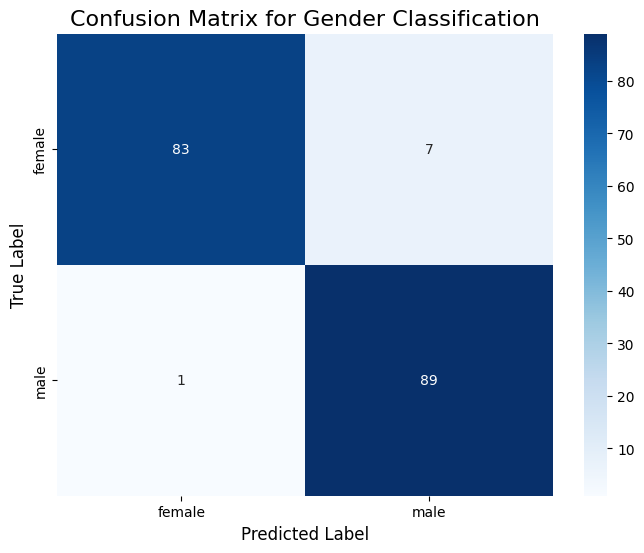


Summary: The model correctly predicted 172 out of 180 samples, achieving an accuracy of 95.56% on the test set.


In [97]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get predictions for the test set using stored variables
y_pred = results['classifier'].predict(results['X_test'])

# Compute the confusion matrix
cm = confusion_matrix(results['y_test'], y_pred)

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
    xticklabels=results['label_encoder'].classes_,yticklabels=results['label_encoder'].classes_)

plt.title('Confusion Matrix for Gender Classification', fontsize=16)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

# Summarizing the result
classes = results['label_encoder'].classes_
total_correct = cm[0,0] + cm[1,1]
total_predictions = cm.sum()
accuracy = (total_correct / total_predictions) * 100
print(f"\nSummary: The model correctly predicted {total_correct} out of {total_predictions} samples, achieving an accuracy of {accuracy:.2f}% on the test set.")

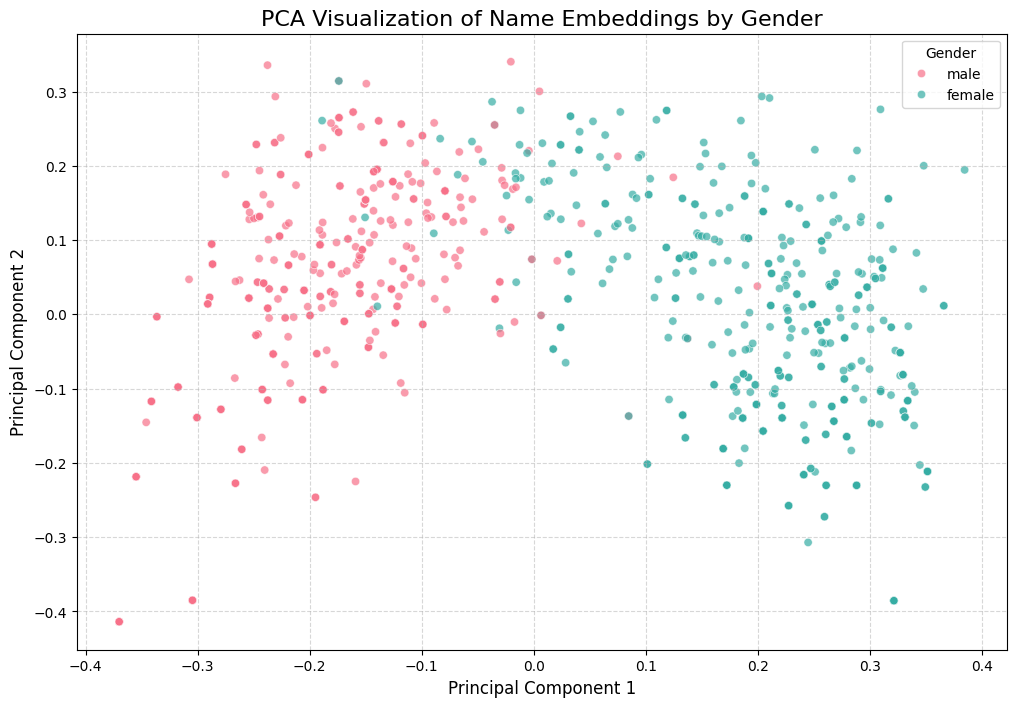

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract data from the results dictionary
reduced_embeddings = results['reduced_embeddings']
gender_labels = results['genders']

# Create a visualization of the embeddings
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=reduced_embeddings[:, 0],
    y=reduced_embeddings[:, 1],
    hue=gender_labels,
    palette='husl',
    alpha=0.7
)

plt.title('PCA Visualization of Name Embeddings by Gender', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend(title='Gender')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# **Hotel recommendation**

In [89]:
hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40552 entries, 0 to 40551
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   travelCode   40552 non-null  int64  
 1   userCode     40552 non-null  int64  
 2   hotel_name   40552 non-null  object 
 3   place        40552 non-null  object 
 4   days         40552 non-null  int64  
 5   hotel_price  40552 non-null  float64
 6   total        40552 non-null  float64
 7   hotel_date   40552 non-null  object 
dtypes: float64(2), int64(3), object(3)
memory usage: 2.5+ MB


In [90]:
# Select relevant hotel features
hotel_features = hotel[['hotel_name', 'place', 'hotel_price', 'days']].drop_duplicates()

print("Selected Hotel Features:")
hotel_features.head()

Selected Hotel Features:


,hotel_name,place,hotel_price,days
0,Hotel A,Florianopolis (SC),313.02,4
1,Hotel K,Salvador (BH),263.41,2
2,Hotel K,Salvador (BH),263.41,3
3,Hotel K,Salvador (BH),263.41,4
4,Hotel A,Florianopolis (SC),313.02,1


In [91]:
# saving the new file
hotel_features.to_csv("hotel_features.csv", index = False)

In [92]:
hotel_features = pd.read_csv("hotel_features.csv")

In [93]:
def suggest_hotels(city, price_bounds, stay_range):
    # Filter the dataset by destination
    matches = hotel_features[hotel_features['place'] == city]

    # Narrow down based on nightly rate
    min_p, max_p = price_bounds
    within_budget = matches[(matches['hotel_price'] >= min_p) & (matches['hotel_price'] <= max_p)]

    # Final filter for the number of days
    min_d, max_d = stay_range
    final_selection = within_budget[within_budget['days'].between(min_d, max_d)]

    return final_selection.head()

# Execute to verify output
suggest_hotels('Recife (PE)', price_bounds=(300, 500), stay_range=(3, 4))

,hotel_name,place,hotel_price,days
7,Hotel AU,Recife (PE),312.83,4
23,Hotel AU,Recife (PE),312.83,3


### **Hotel Recommendation Engine Summary**

**1. What is it?**

Instead of a generic list of hotels, we built a **Personalized Recommendation Engine**. It acts like a digital travel agent that filters thousands of options to find the perfect match for a specific trip.

**2. How does it work?**

To give a recommendation, the system looks at three key factors simultaneously:
*   **Location Match:** It only shows hotels in the traveler's specific destination city (e.g., Recife or Salvador).
*   **Budget Alignment:** It filters out any hotels that fall outside the traveler's preferred price-per-night range.
*   **Stay Optimization:** It ensures the hotel has availability or pricing structures that match the intended number of travel days.

**3. Why is this valuable?**

*   **Saves Time:** Travelers don't have to scroll through irrelevant options.
*   **Increases Conversion:** By showing the most relevant hotels first, travelers are more likely to complete a booking.
*   **Better User Experience:** It provides a seamless transition from booking a flight to finding the right place to stay.